In [40]:
import tensorflow as tf
import tensorflow_decision_forests as tfdf
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Set up notebook to display multiple outputs in one cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
from IPython.display import display

# Comment this if the data visualisations doesn't work on your side
%matplotlib inline

# Supress unnecessary warnings so that presentation looks clean
import warnings
warnings.filterwarnings('ignore')

In [9]:
train_file_path = "/Users/scottkeighley/Desktop/MSDS_422/allstate-claims-severity/train.csv"
dataset = pd.read_csv(train_file_path) 

#Read test dataset
test_file_path = "/Users/scottkeighley/Desktop/MSDS_422/allstate-claims-severity/test.csv"
dataset_test = pd.read_csv(test_file_path)
#Save the id's for submission file
ID = dataset_test['id']
#Drop unnecessary columns
dataset_test.drop('id',axis=1,inplace=True)

#Print all rows and columns. Dont hide any
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

#Display the first five rows to get a feel of the data
print(dataset.head(5))

#Learning : cat1 to cat116 contain alphabets

   id cat1 cat2 cat3 cat4 cat5 cat6 cat7 cat8 cat9 cat10 cat11 cat12 cat13  \
0   1    A    B    A    B    A    A    A    A    B     A     B     A     A   
1   2    A    B    A    A    A    A    A    A    B     B     A     A     A   
2   5    A    B    A    A    B    A    A    A    B     B     B     B     B   
3  10    B    B    A    B    A    A    A    A    B     A     A     A     A   
4  11    A    B    A    B    A    A    A    A    B     B     A     B     A   

  cat14 cat15 cat16 cat17 cat18 cat19 cat20 cat21 cat22 cat23 cat24 cat25  \
0     A     A     A     A     A     A     A     A     A     B     A     A   
1     A     A     A     A     A     A     A     A     A     A     A     A   
2     A     A     A     A     A     A     A     A     A     A     A     A   
3     A     A     A     A     A     A     A     A     A     B     A     A   
4     A     A     A     A     A     A     A     A     A     B     A     A   

  cat26 cat27 cat28 cat29 cat30 cat31 cat32 cat33 cat34 cat35 cat36 

In [35]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188318 entries, 0 to 188317
Columns: 131 entries, cat1 to loss
dtypes: float64(15), object(116)
memory usage: 188.2+ MB


## Data Statistics

In [12]:
# Size of the dataframe

print(dataset.shape)

# We can see that there are 188318 instances having 132 attributes

#Drop the first column 'id' since it just has serial numbers. Not useful in the prediction process.
dataset = dataset.iloc[:,1:]

#Learning : Data is loaded successfully as dimensions match the data description

(188318, 132)


In [14]:
# Statistical description

print(dataset.describe())

# Learning :
# No attribute in continuous columns is missing as count is 188318 for all, all rows can be used
# No negative values are present. Tests such as chi2 can be used
# Statistics not displayed for categorical data

               cont1          cont2          cont3          cont4  \
count  188318.000000  188318.000000  188318.000000  188318.000000   
mean        0.493861       0.507188       0.498918       0.491812   
std         0.187640       0.207202       0.202105       0.211292   
min         0.000016       0.001149       0.002634       0.176921   
25%         0.346090       0.358319       0.336963       0.327354   
50%         0.475784       0.555782       0.527991       0.452887   
75%         0.623912       0.681761       0.634224       0.652072   
max         0.984975       0.862654       0.944251       0.954297   

               cont5          cont6          cont7          cont8  \
count  188318.000000  188318.000000  188318.000000  188318.000000   
mean        0.487428       0.490945       0.484970       0.486437   
std         0.209027       0.205273       0.178450       0.199370   
min         0.281143       0.012683       0.069503       0.236880   
25%         0.281143       0.3361

count    188318.000000
mean          7.685908
std           0.811309
min           0.512824
25%           7.094617
50%           7.657552
75%           8.259729
max          11.703655
Name: loss, dtype: float64


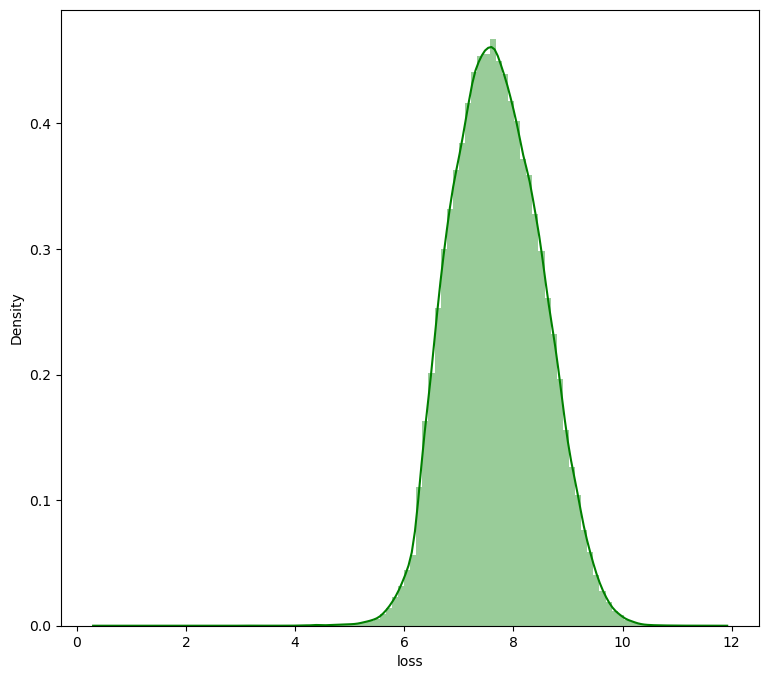

In [59]:
print(dataset['loss'].describe())
plt.figure(figsize=(9, 8))
sns.distplot(dataset['loss'], color='g', bins=100, hist_kws={'alpha': 0.4});

In [42]:
# ============ CONFIG ============
TARGET = "loss"
ID_COL = "id"
MAX_CATS_FOR_TESTS = 60         # skip ANOVA on super high-cardinality cats
MIN_SAMPLES_PER_LEVEL = 3       # drop tiny groups for ANOVA/Kruskal
N_TOP_CORR = 20                 # how many numeric features to plot vs target
PLOT_SAMPLE = 30000             # sample size for scatter plots if data is big
RANDOM_STATE = 42
SHOW_PLOTS = True               # flip to False if you only want tables
# ===============================

# --- Column sets (robust to dtype quirks) ---
all_cols = dataset.columns.tolist()
cat_cols = [c for c in all_cols if c.startswith('cat')] or dataset.select_dtypes(include=['object','category']).columns.tolist()
num_cols = [c for c in all_cols if c.startswith('cont')]
# fallbacks in case cont* detection misses something numeric
num_cols = sorted(set(num_cols) | set(dataset.select_dtypes(include=[np.number]).columns) - {TARGET, ID_COL})

print(f"Rows: {len(dataset):,} | Columns: {len(all_cols)}")
print(f"Categorical cols: {len(cat_cols)} | Numeric cols: {len(num_cols)} (+ target)")
print()

Rows: 188,318 | Columns: 131
Categorical cols: 116 | Numeric cols: 14 (+ target)



In [44]:
# --- Memory-friendly dtypes for cats ---
for c in cat_cols:
    if dataset[c].dtype != "category":
        dataset[c] = dataset[c].astype("category")

# --- Basic health checks ---
def missing_summary(df: pd.DataFrame) -> pd.DataFrame:
    out = (df.isna().sum()
           .to_frame("n_missing")
           .assign(pct=lambda d: d["n_missing"] / len(df))
           .sort_values(["n_missing","pct"], ascending=False))
    return out[out["n_missing"] > 0]

print("Missing values (train):")
display(missing_summary(dataset))

Missing values (train):


,n_missing,pct


In [46]:
# Zero-variance & cardinality
card = dataset[cat_cols].nunique(dropna=False).sort_values(ascending=False).to_frame("nunique")
zerovar_num = [c for c in num_cols if dataset[c].nunique(dropna=False) <= 1]
print("\nZero-variance numeric features:", zerovar_num)
print("\nTop categorical cardinalities:")
display(card.head(15))


Zero-variance numeric features: []

Top categorical cardinalities:


,nunique
cat116,326
cat110,131
cat109,84
cat113,61
cat112,51
cat115,23
cat107,20
cat105,20
cat101,19
cat114,19


<Figure size 600x400 with 0 Axes>

(array([1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 2.0000e+00, 0.0000e+00, 1.0000e+00,
        2.0000e+00, 0.0000e+00, 0.0000e+00, 3.0000e+00, 1.0000e+00,
        1.0000e+00, 4.0000e+00, 0.0000e+00, 2.0000e+00, 1.1000e+01,
        1.9000e+01, 1.3000e+01, 2.2000e+01, 3.5000e+01, 4.9000e+01,
        9.7000e+01, 1.7700e+02, 3.7700e+02, 7.7000e+02, 1.4280e+03,
        2.6330e+03, 5.5960e+03, 8.3020e+03, 1.0927e+04, 1.2709e+04,
        1.4201e+04, 1.5583e+04, 1.6143e+04, 1.6053e+04, 1.5192e+04,
        1.4004e+04, 1.2744e+04, 1.1208e+04, 9.1520e+03, 7.3790e+03,
        5.0940e+03, 3.6280e+03, 2.2420e+03, 1.2800e+03, 6.5600e+02,
        3.3400e+02, 1.4700e+02, 5.2000e+01, 2.1000e+01, 1.0000e+01,
        6.0000e+00, 3.0000e+00, 1.0000e+00, 1.0000e+00, 2.0000e+00]),
 array([ 0.51282363,  0.69933749,  0.88585135,  1.07236521,  1.25887907,
         1.44539293,  1.6319068 ,  1.81842066,  2.00493452,  2.19144838,
         2.37796224,  2.5644761 ,  2

Text(0.5, 1.0, 'loss distribution')

Text(0.5, 0, 'loss')

Text(0, 0.5, 'count')

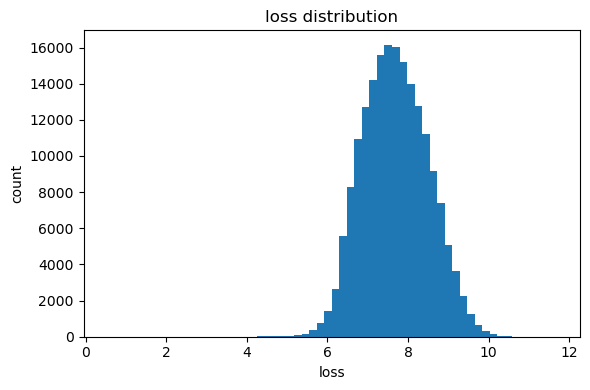

<Figure size 600x400 with 0 Axes>

(array([1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 1.0000e+00, 1.0000e+00, 0.0000e+00,
        0.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 1.0000e+00, 3.0000e+00, 1.0000e+00,
        0.0000e+00, 4.0000e+00, 0.0000e+00, 2.0000e+00, 1.1000e+01,
        1.9000e+01, 1.3000e+01, 2.8000e+01, 3.8000e+01, 7.0000e+01,
        1.6600e+02, 3.9500e+02, 1.0170e+03, 2.2180e+03, 6.5840e+03,
        1.2496e+04, 1.7988e+04, 2.2384e+04, 2.5636e+04, 2.6250e+04,
        2.4023e+04, 2.0702e+04, 1.4948e+04, 8.3920e+03, 3.6220e+03,
        1.0550e+03, 2.0600e+02, 2.9000e+01, 7.0000e+00, 4.0000e+00]),
 array([0.41397786, 0.44944305, 0.48490825, 0.52037345, 0.55583865,
        0.59130385, 0.62676905, 0.66223425, 0.69769944, 0.73316464,
        0.76862984, 0.80409504, 0.83956024, 0.

Text(0.5, 1.0, 'log1p(loss) distribution')

Text(0.5, 0, 'log1p(loss)')

Text(0, 0.5, 'count')

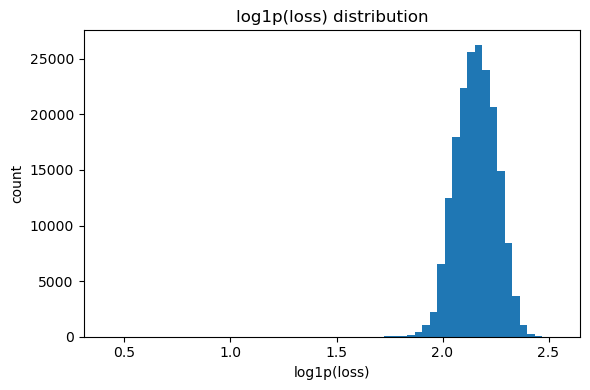

In [50]:
# --- Target distribution (raw + log1p) ---
if SHOW_PLOTS:
    plt.figure(figsize=(6,4))
    plt.hist(dataset[TARGET].values, bins=60)
    plt.title(f"{TARGET} distribution")
    plt.xlabel(TARGET); plt.ylabel("count")
    plt.tight_layout(); plt.show();

    plt.figure(figsize=(6,4))
    plt.hist(np.log1p(dataset[TARGET].values), bins=60)
    plt.title(f"log1p({TARGET}) distribution")
    plt.xlabel(f"log1p({TARGET})"); plt.ylabel("count")
    plt.tight_layout(); plt.show();

In [52]:
# --- Numeric features: summary & correlations with target ---
num_desc = dataset[num_cols].describe().T
num_desc["skew"] = dataset[num_cols].skew()
num_desc["kurt"] = dataset[num_cols].kurtosis()
print("\nNumeric summary:")
display(num_desc)


Numeric summary:


,count,mean,std,min,25%,50%,75%,max,skew,kurt
cont1,188318.0,0.493861,0.187640,0.000016,0.346090,0.475784,0.623912,0.984975,0.516424,-0.101712
cont10,188318.0,0.498066,0.185877,0.000000,0.364580,0.461190,0.614590,0.994980,0.355001,-0.851664
cont11,188318.0,0.493511,0.209737,0.035321,0.310961,0.457203,0.678924,0.998742,0.280821,-1.050055
cont12,188318.0,0.493150,0.209427,0.036232,0.311661,0.462286,0.675759,0.998484,0.291992,-1.028374
cont13,188318.0,0.493138,0.212777,0.000228,0.315758,0.363547,0.689974,0.988494,0.380742,-1.349334
cont14,188318.0,0.495717,0.222488,0.179722,0.294610,0.407403,0.724623,0.844848,0.248674,-1.530071
cont2,188318.0,0.507188,0.207202,0.001149,0.358319,0.555782,0.681761,0.862654,-0.310941,-0.895657
cont3,188318.0,0.498918,0.202105,0.002634,0.336963,0.527991,0.634224,0.944251,-0.010002,-0.606562
cont4,188318.0,0.491812,0.211292,0.176921,0.327354,0.452887,0.652072,0.954297,0.416096,-0.965424
cont5,188318.0,0.487428,0.209027,0.281143,0.281143,0.422268,0.643315,0.983674,0.681622,-0.876877


In [54]:
# Spearman is robust for monotone relations
spearman = dataset[num_cols + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("\nTop numeric correlations (Spearman) with target:")
display(spearman.head(N_TOP_CORR).to_frame("spearman_corr"))


Top numeric correlations (Spearman) with target:


,spearman_corr
cont2,0.080066
cont3,0.068353
cont7,0.054928
cont11,0.054323
cont12,0.053624
cont4,-0.027878
cont8,0.027495
cont6,0.019697
cont1,-0.017641
cont5,-0.015114


<Figure size 800x600 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Top 20 numeric features by |Spearman| corr with loss')

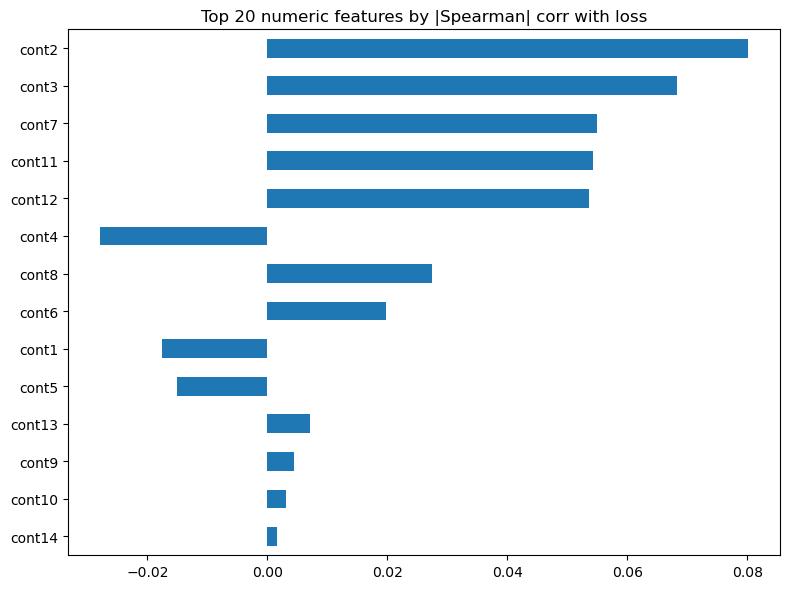

<Figure size 600x400 with 0 Axes>

Text(0.5, 1.0, 'cont2 vs loss')

Text(0.5, 0, 'cont2')

Text(0, 0.5, 'loss')

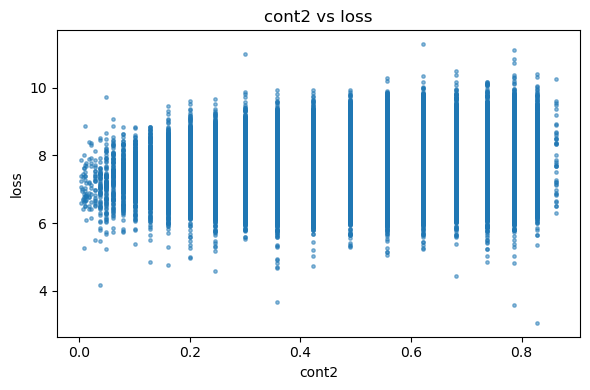

<Figure size 600x400 with 0 Axes>

Text(0.5, 1.0, 'cont3 vs loss')

Text(0.5, 0, 'cont3')

Text(0, 0.5, 'loss')

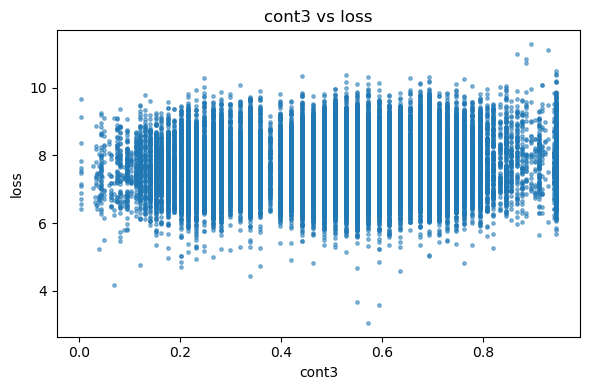

<Figure size 600x400 with 0 Axes>

Text(0.5, 1.0, 'cont7 vs loss')

Text(0.5, 0, 'cont7')

Text(0, 0.5, 'loss')

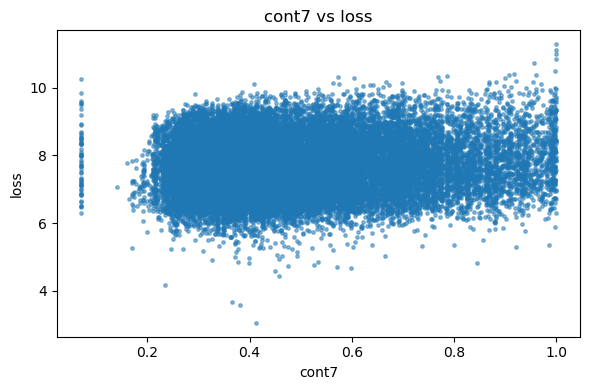

<Figure size 600x400 with 0 Axes>

Text(0.5, 1.0, 'cont11 vs loss')

Text(0.5, 0, 'cont11')

Text(0, 0.5, 'loss')

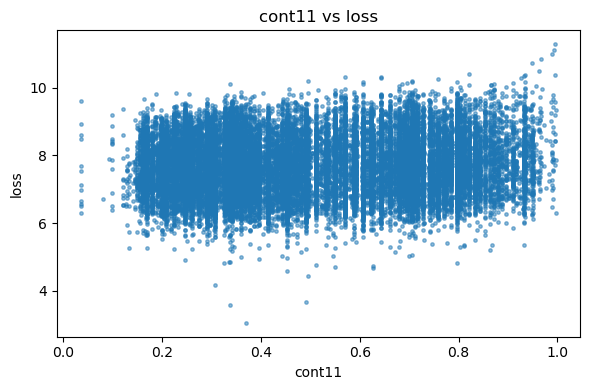

<Figure size 600x400 with 0 Axes>

Text(0.5, 1.0, 'cont12 vs loss')

Text(0.5, 0, 'cont12')

Text(0, 0.5, 'loss')

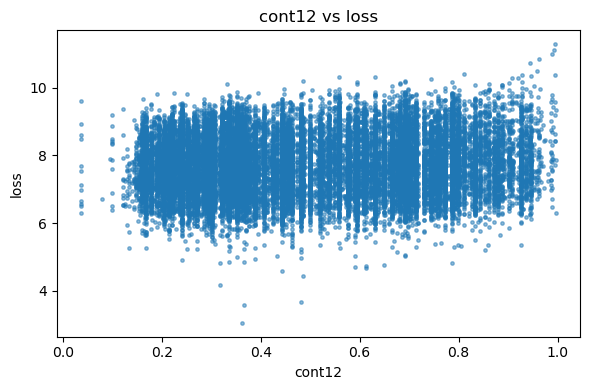

<Figure size 600x400 with 0 Axes>

Text(0.5, 1.0, 'cont4 vs loss')

Text(0.5, 0, 'cont4')

Text(0, 0.5, 'loss')

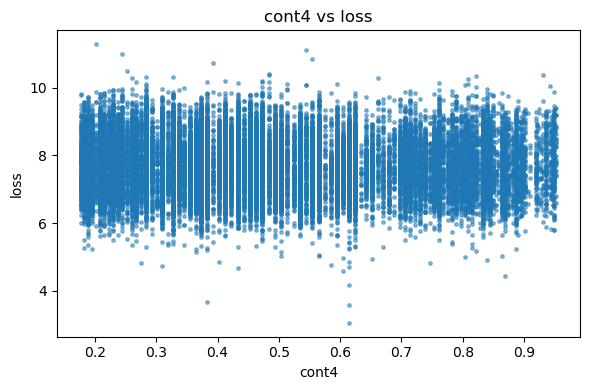

In [56]:
if SHOW_PLOTS:
    # Bar chart of top correlations
    top_corr = spearman.head(N_TOP_CORR)
    plt.figure(figsize=(8,6))
    top_corr[::-1].plot(kind="barh")  # reversed for readability
    plt.title(f"Top {N_TOP_CORR} numeric features by |Spearman| corr with {TARGET}")
    plt.tight_layout(); plt.show()

    # Scatter plots for the top 6 numeric features
    top6 = top_corr.index[:6].tolist()
    sample_idx = dataset.sample(min(PLOT_SAMPLE, len(dataset)), random_state=RANDOM_STATE).index
    for col in top6:
        plt.figure(figsize=(6,4))
        plt.scatter(dataset.loc[sample_idx, col], dataset.loc[sample_idx, TARGET], s=6, alpha=0.5)
        plt.title(f"{col} vs {TARGET}")
        plt.xlabel(col); plt.ylabel(TARGET)
        plt.tight_layout(); plt.show()

<Axes: ylabel='cont1'>

<Axes: ylabel='cont2'>

<Axes: ylabel='cont3'>

<Axes: ylabel='cont4'>

<Axes: ylabel='cont5'>

<Axes: ylabel='cont6'>

... (4 outputs left out)

<Axes: ylabel='cont11'>

<Axes: ylabel='cont12'>

<Axes: ylabel='cont13'>

<Axes: ylabel='cont14'>

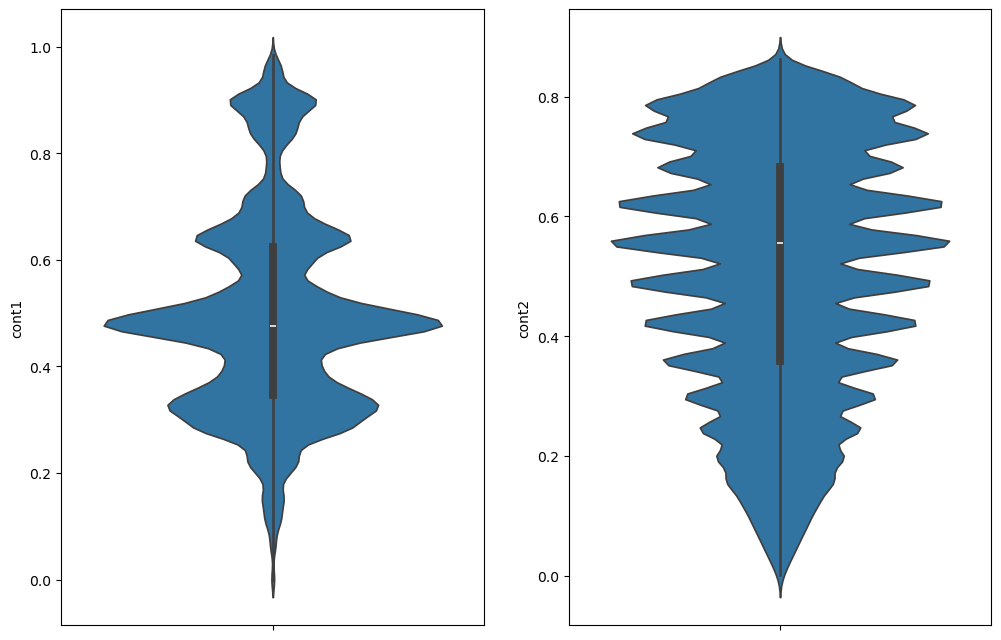

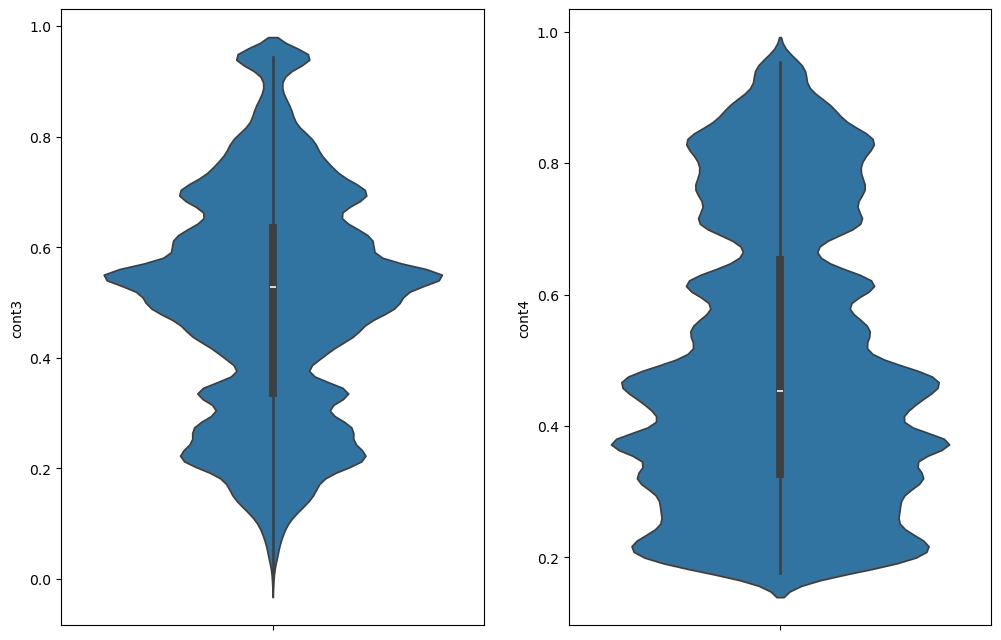

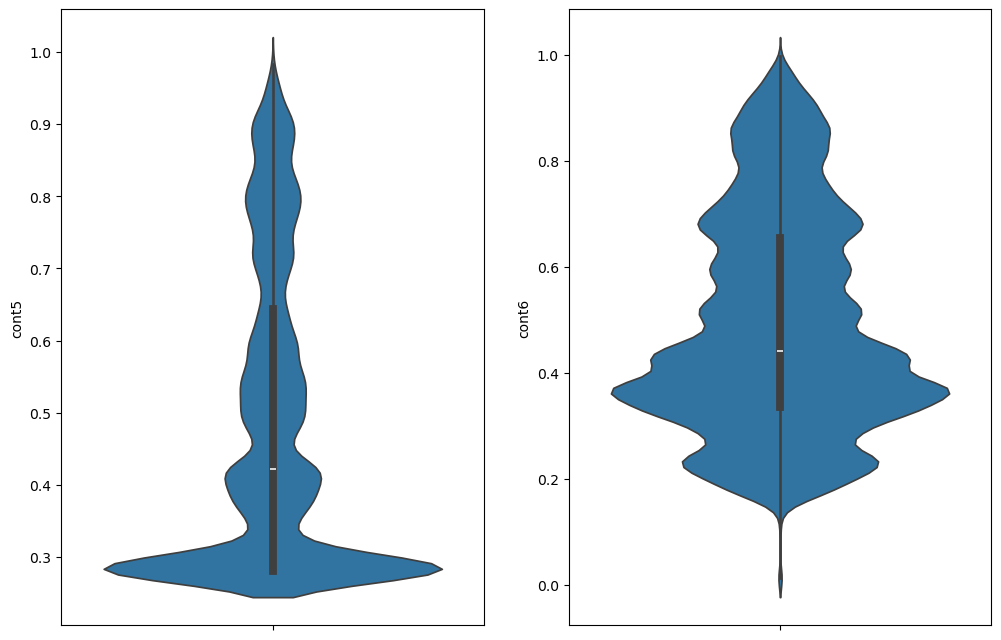

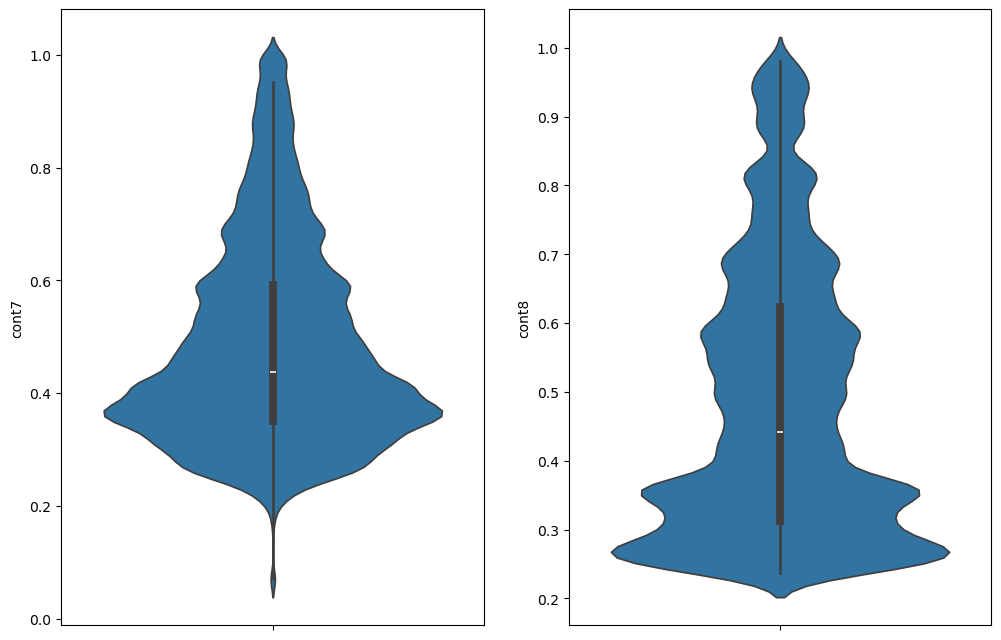

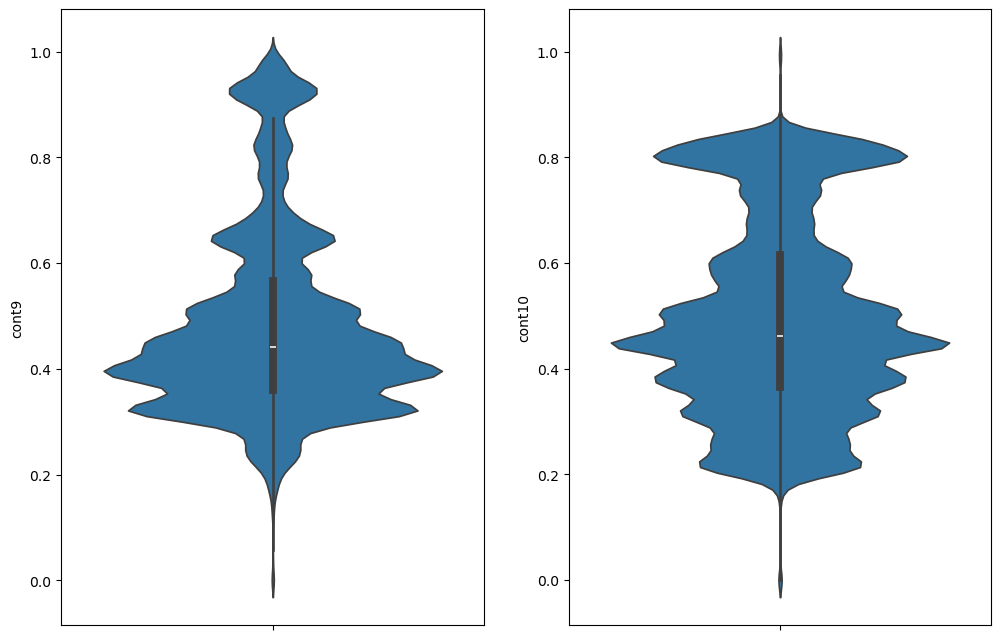

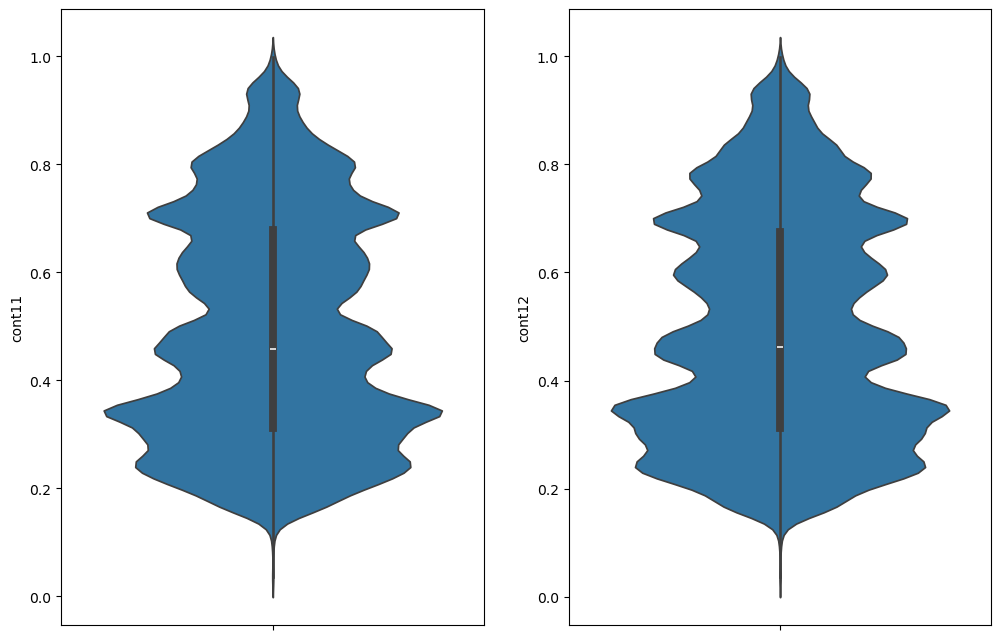

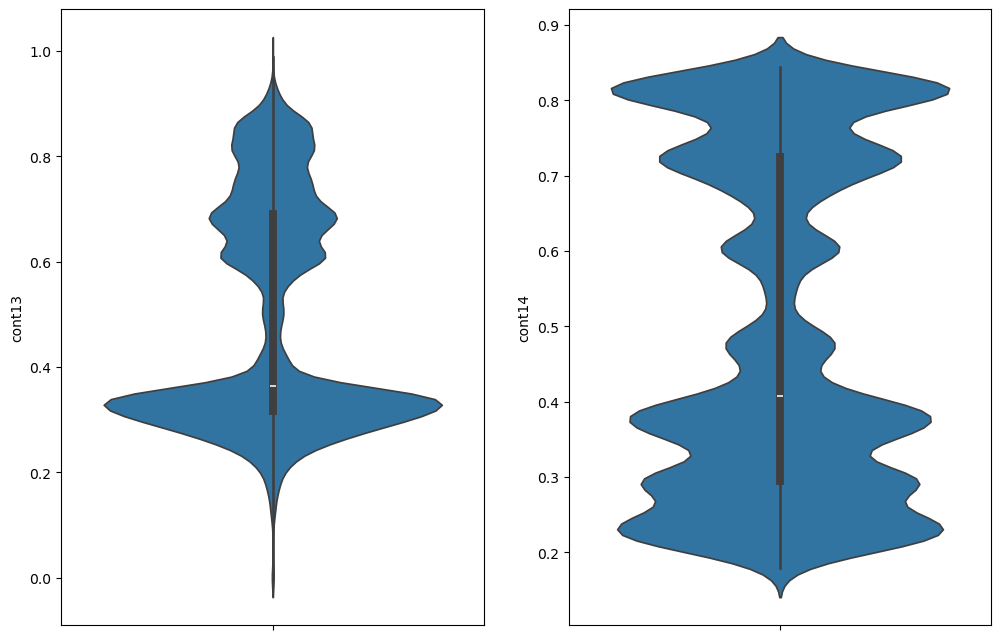

In [18]:
# We will visualize all the continuous attributes using Violin Plot - a combination of box and density plots

import numpy

#import plotting libraries
import seaborn as sns
import matplotlib.pyplot as plt

#range of features considered
split = 116 

#number of features considered
size = 15

#create a dataframe with only continuous features
data=dataset.iloc[:,split:] 

#get the names of all the columns
cols=data.columns 

#Plot violin for all attributes in a 7x2 grid
n_cols = 2
n_rows = 7

for i in range(n_rows):
    fg,ax = plt.subplots(nrows=1,ncols=n_cols,figsize=(12, 8))
    for j in range(n_cols):
        sns.violinplot(y=cols[i*n_cols+j], data=dataset, ax=ax[j])


#cont1 has many values close to 0.5
#cont2 has a pattern where there a several spikes at specific points
#cont5 has many values near 0.3
#cont14 has a distinct pattern. 0.22 and 0.82 have a lot of concentration
#loss distribution must be converted to normal

## Data Transformation

<Axes: ylabel='loss'>

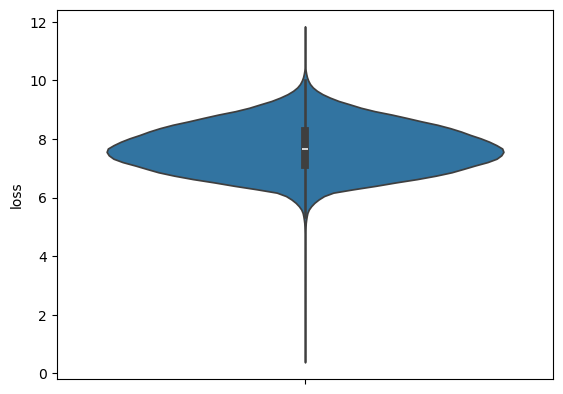

In [22]:
#log1p function applies log(1+x) to all elements of the column
dataset["loss"] = numpy.log1p(dataset["loss"])
#visualize the transformed column
sns.violinplot(data=dataset,y="loss")  
plt.show()

#Plot shows that skew is corrected to a large extent

## Correlation

In [25]:
# Correlation tells relation between two attributes.
# Correlation requires continous data. Hence, ignore categorical data

# Calculates pearson co-efficient for all combinations
data_corr = data.corr()

# Set the threshold to select only highly correlated attributes
threshold = 0.5

# List of pairs along with correlation above threshold
corr_list = []

#Search for the highly correlated pairs
for i in range(0,size): #for 'size' features
    for j in range(i+1,size): #avoid repetition
        if (data_corr.iloc[i,j] >= threshold and data_corr.iloc[i,j] < 1) or (data_corr.iloc[i,j] < 0 and data_corr.iloc[i,j] <= -threshold):
            corr_list.append([data_corr.iloc[i,j],i,j]) #store correlation and columns index

#Sort to show higher ones first            
s_corr_list = sorted(corr_list,key=lambda x: -abs(x[0]))

#Print correlations and column names
for v,i,j in s_corr_list:
    print ("%s and %s = %.2f" % (cols[i],cols[j],v))

# Strong correlation is observed between the following pairs
# This represents an opportunity to reduce the feature set through transformations such as PCA

cont11 and cont12 = 0.99
cont1 and cont9 = 0.93
cont6 and cont10 = 0.88
cont6 and cont13 = 0.82
cont1 and cont10 = 0.81
cont6 and cont9 = 0.80
cont9 and cont10 = 0.79
cont6 and cont12 = 0.79
cont6 and cont11 = 0.77
cont1 and cont6 = 0.76
cont7 and cont11 = 0.75
cont7 and cont12 = 0.74
cont10 and cont12 = 0.71
cont10 and cont13 = 0.71
cont10 and cont11 = 0.70
cont6 and cont7 = 0.66
cont9 and cont13 = 0.64
cont9 and cont12 = 0.63
cont1 and cont12 = 0.61
cont9 and cont11 = 0.61
cont1 and cont11 = 0.60
cont1 and cont13 = 0.53
cont4 and cont8 = 0.53


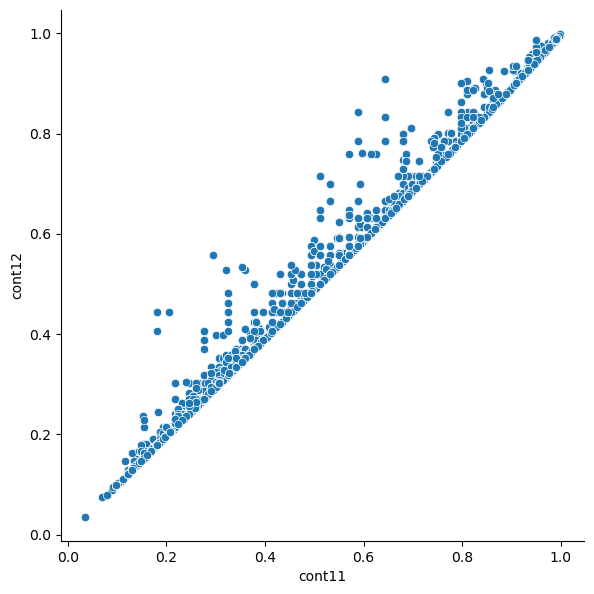

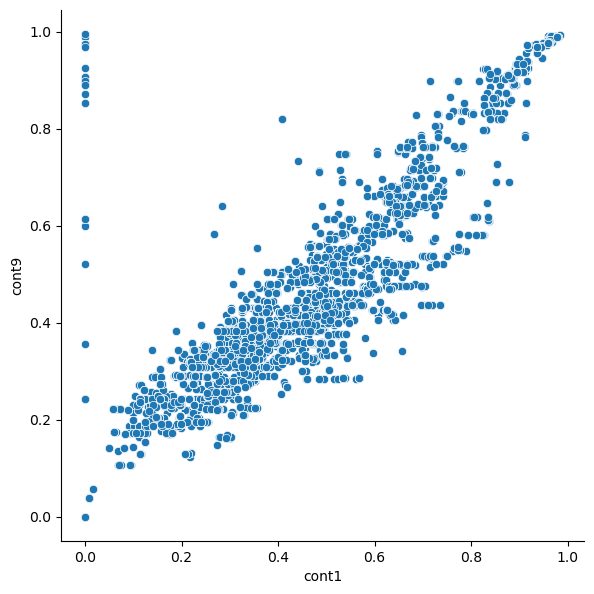

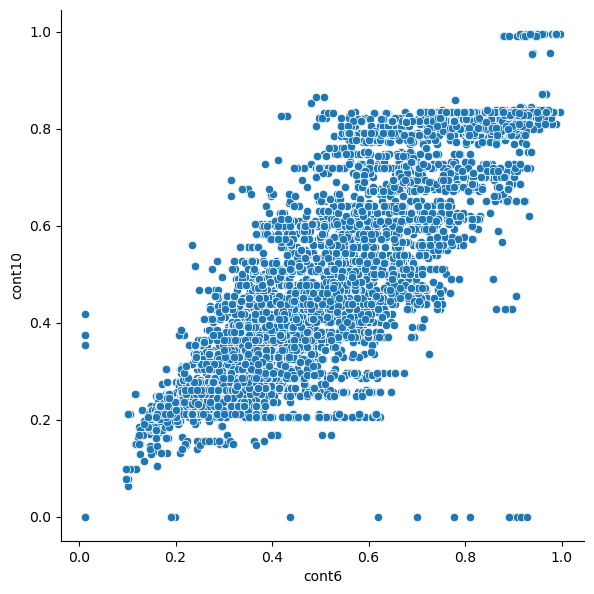

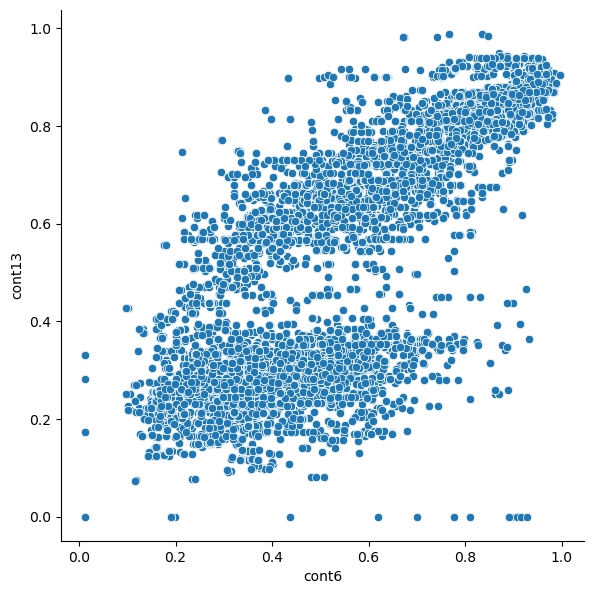

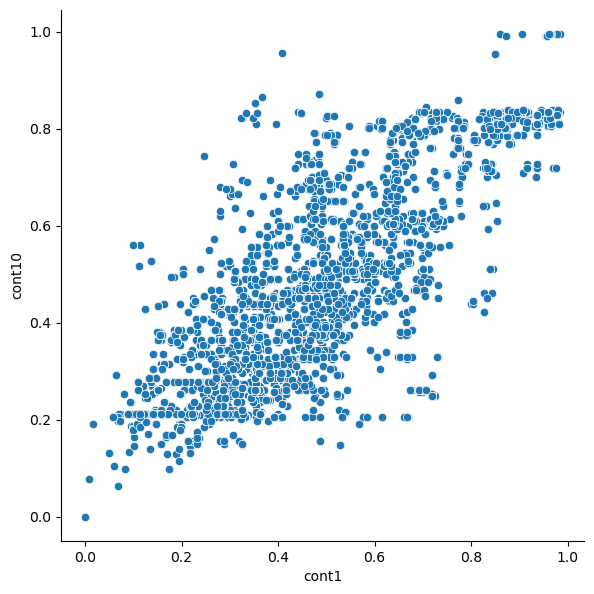

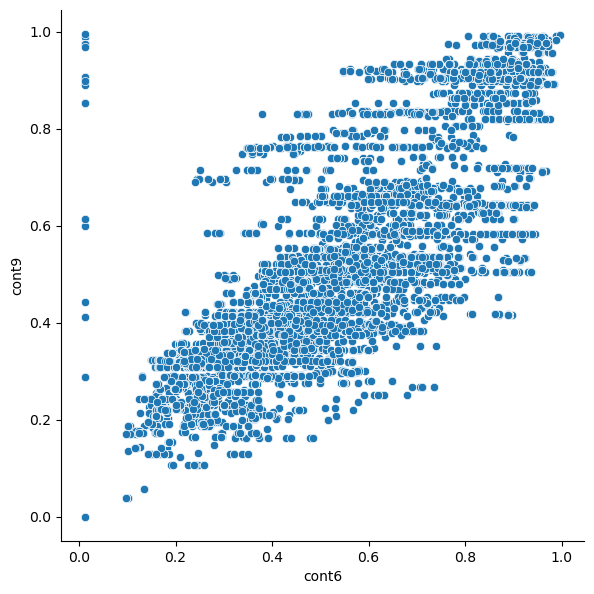

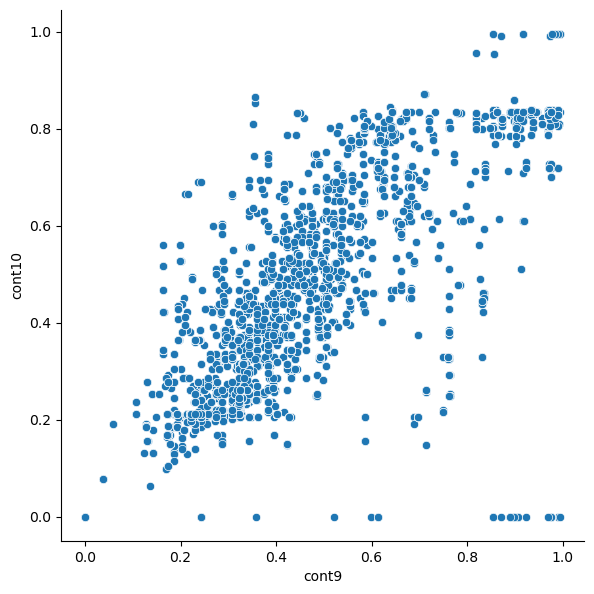

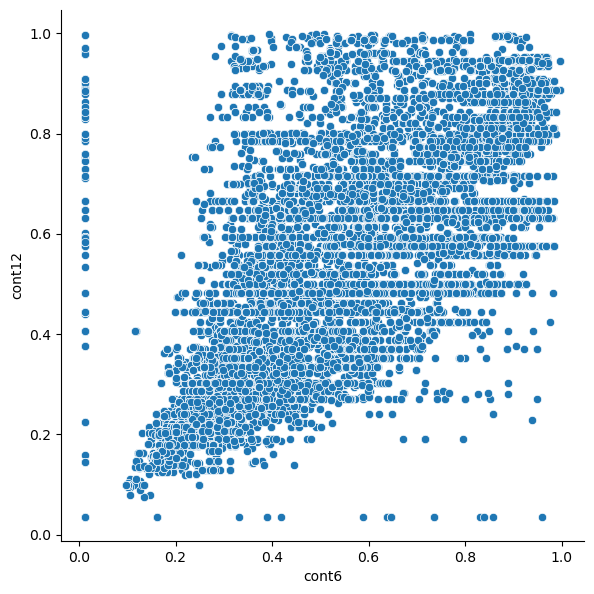

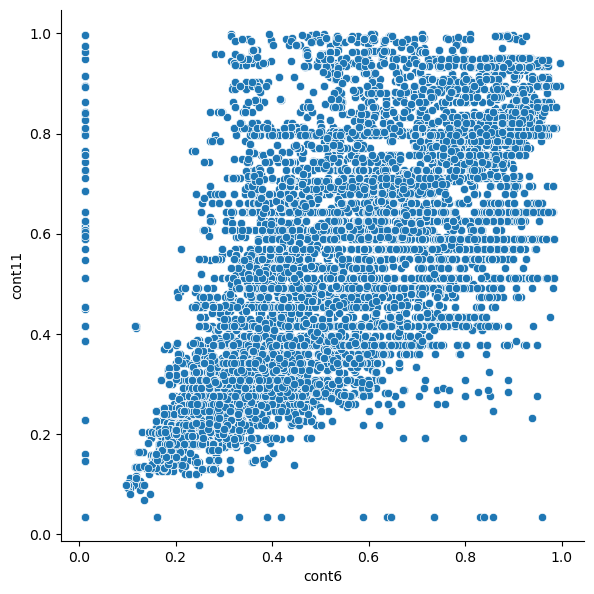

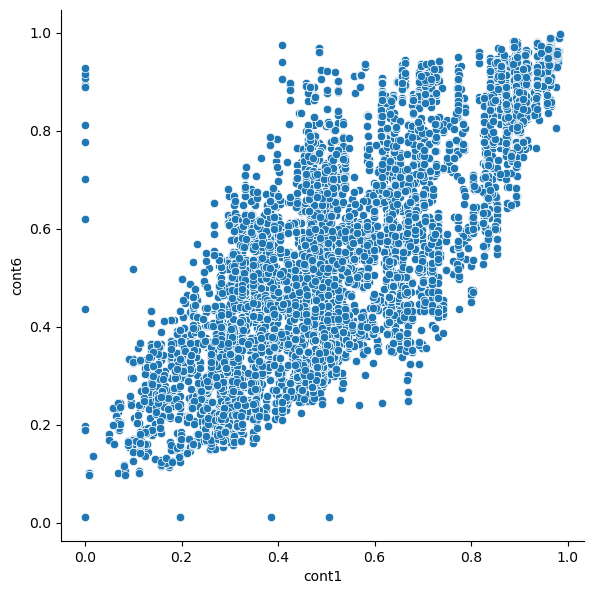

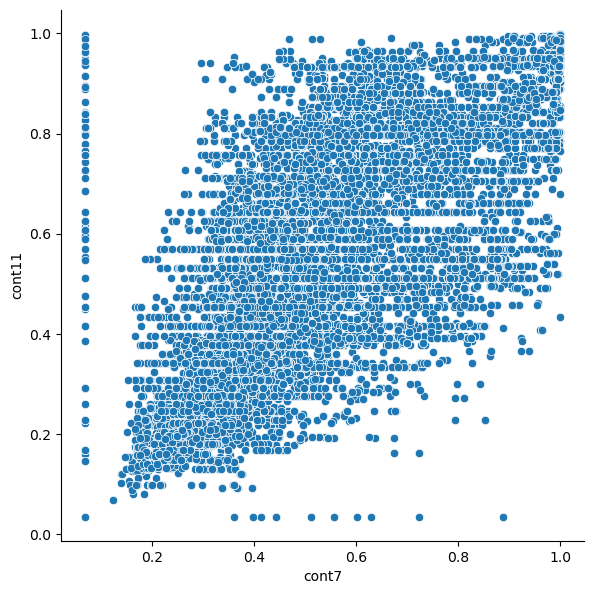

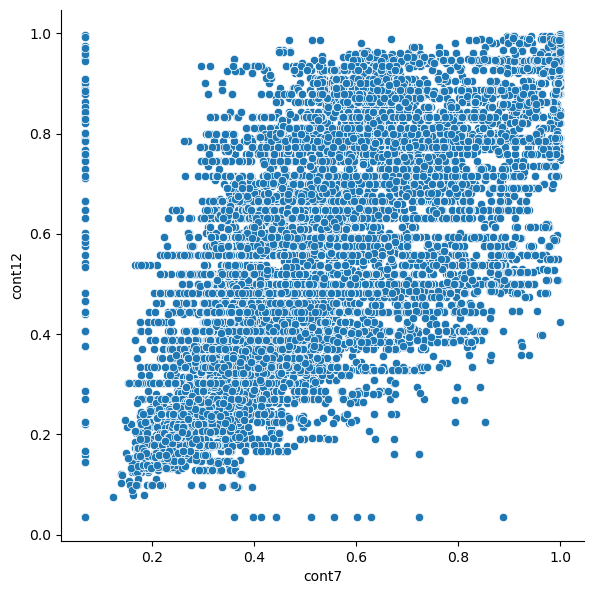

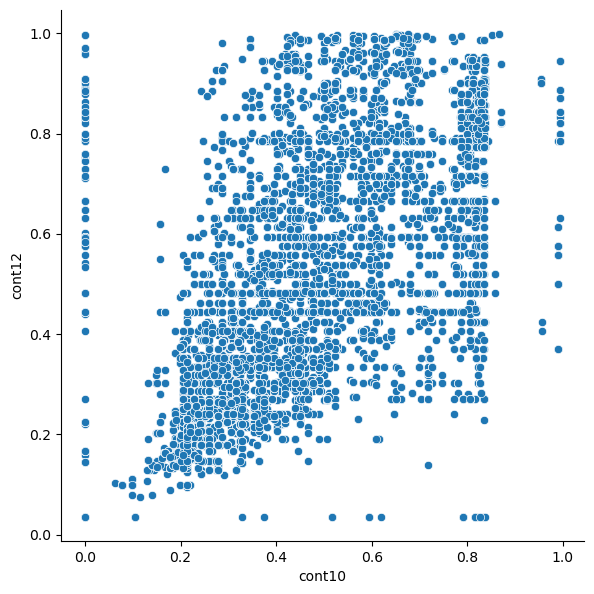

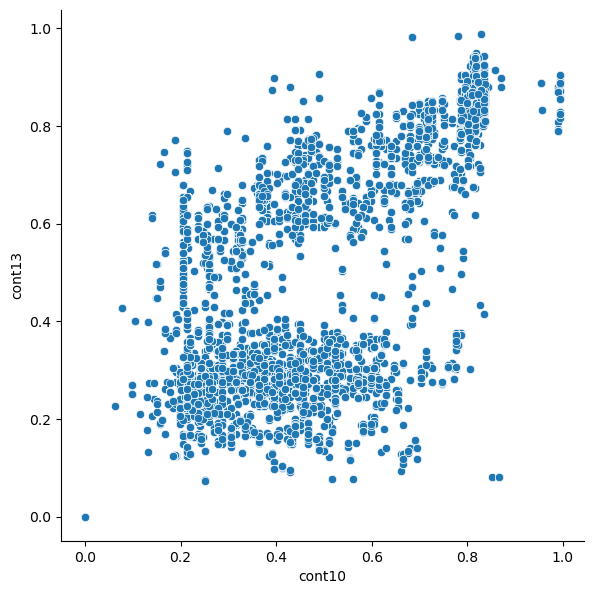

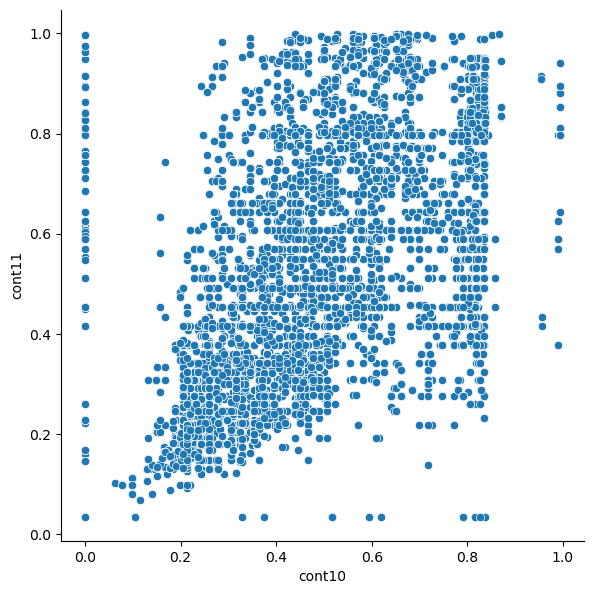

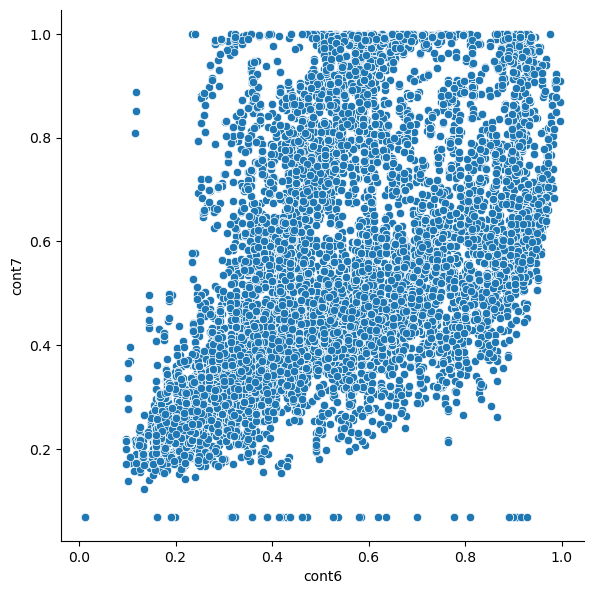

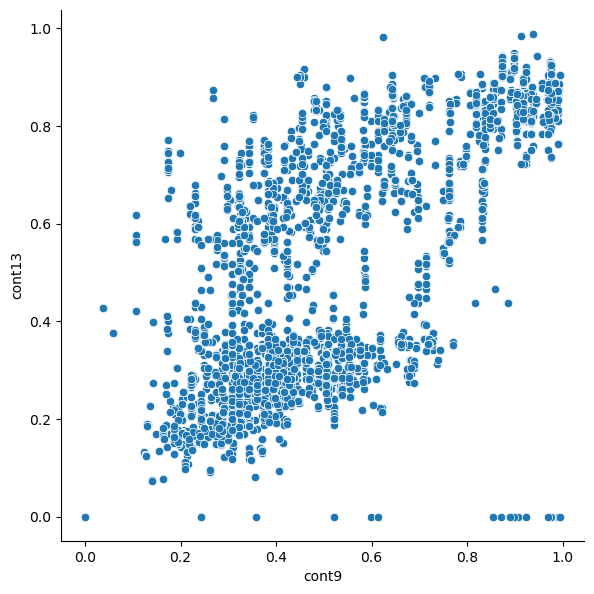

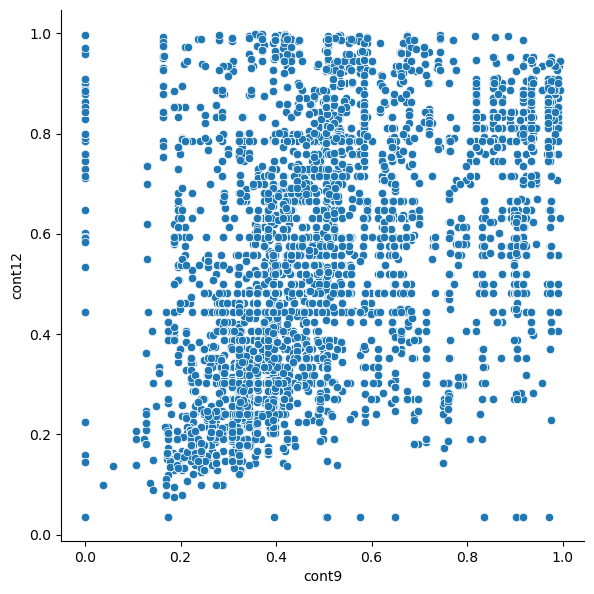

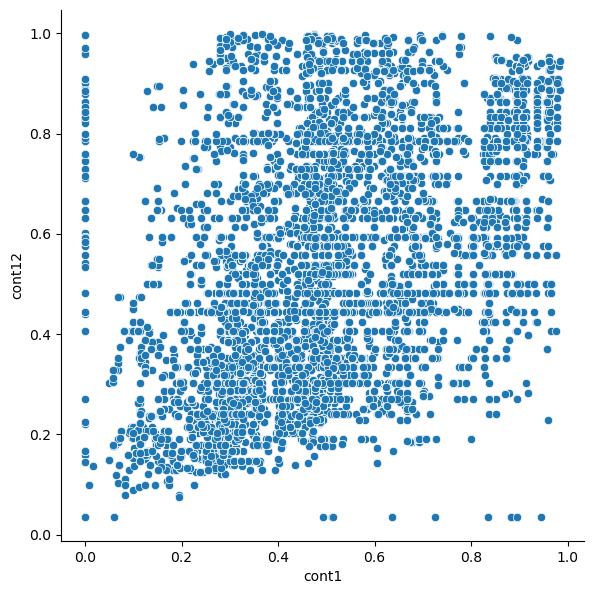

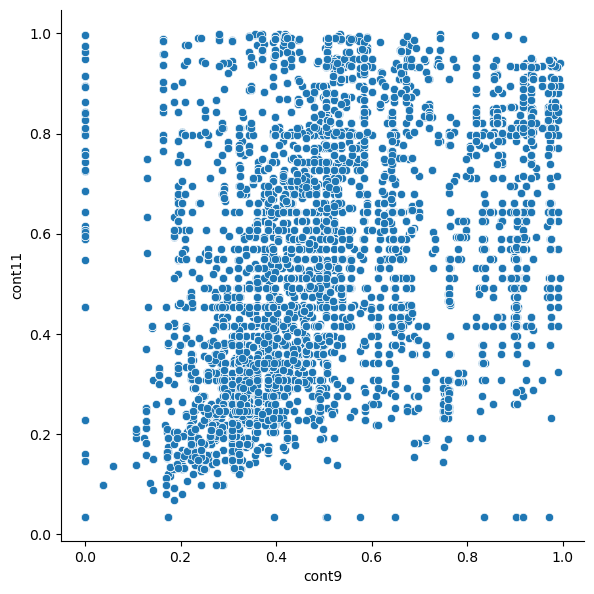

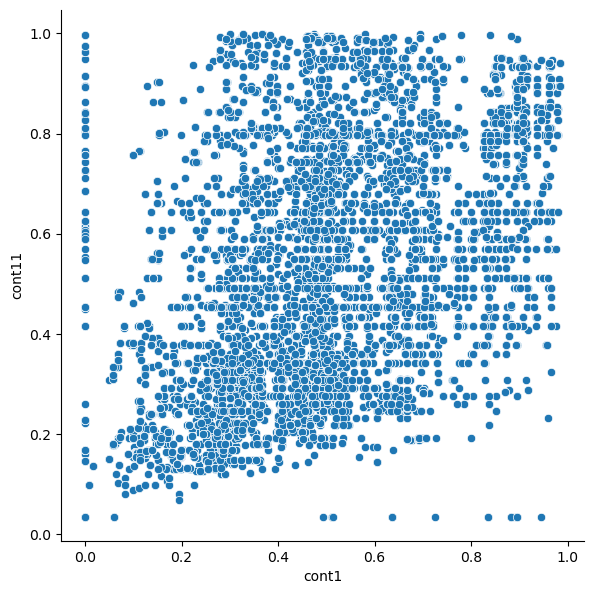

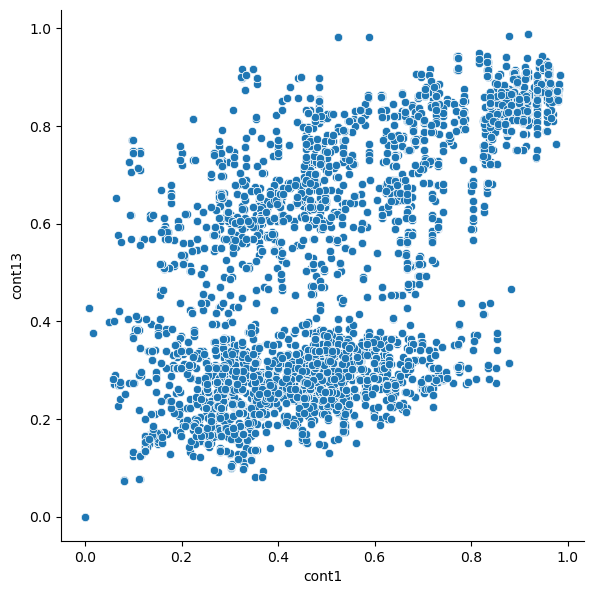

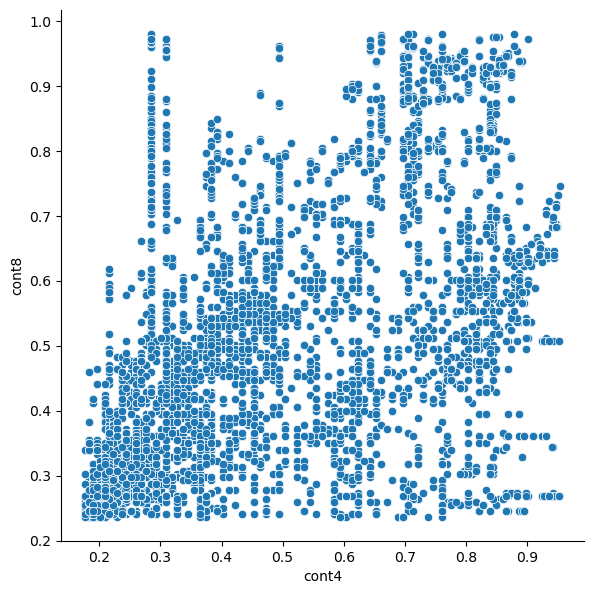

In [27]:
# Scatter plot of only the highly correlated pairs
for v,i,j in s_corr_list:
    sns.pairplot(dataset, size=6, x_vars=cols[i],y_vars=cols[j] )
    plt.show()

#cont11 and cont12 give an almost linear pattern...one must be removed
#cont1 and cont9 are highly correlated ...either of them could be safely removed 
#cont6 and cont10 show very good correlation too

<Axes: xlabel='cat1', ylabel='count'>

<Axes: xlabel='cat2', ylabel='count'>

<Axes: xlabel='cat3', ylabel='count'>

<Axes: xlabel='cat4', ylabel='count'>

<Axes: xlabel='cat5', ylabel='count'>

<Axes: xlabel='cat6', ylabel='count'>

... (106 outputs left out)

<Axes: xlabel='cat113', ylabel='count'>

<Axes: xlabel='cat114', ylabel='count'>

<Axes: xlabel='cat115', ylabel='count'>

<Axes: xlabel='cat116', ylabel='count'>

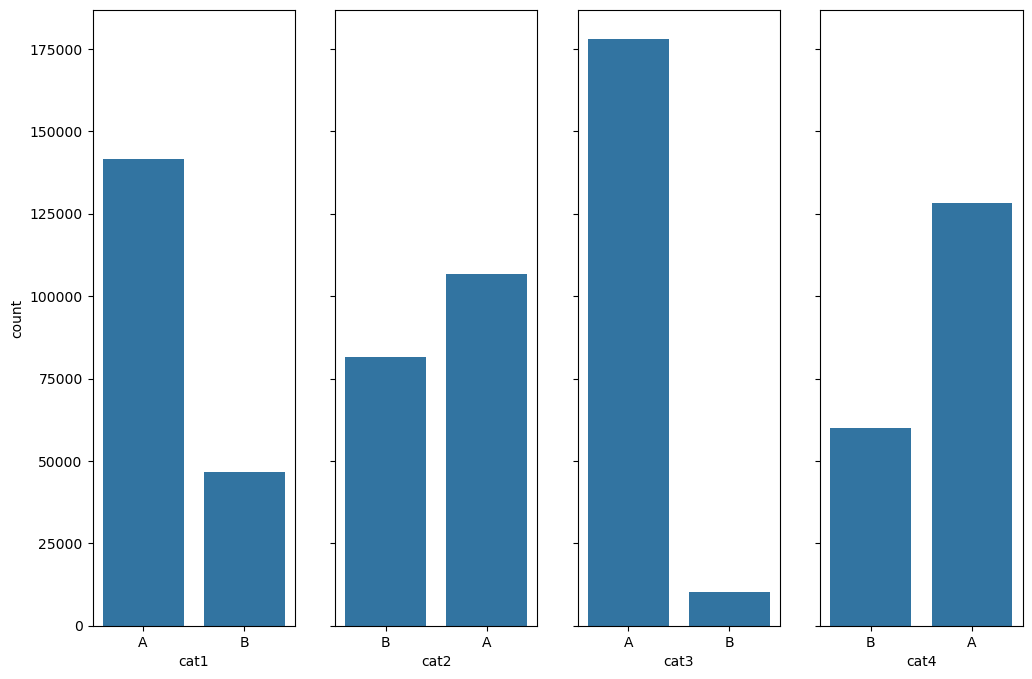

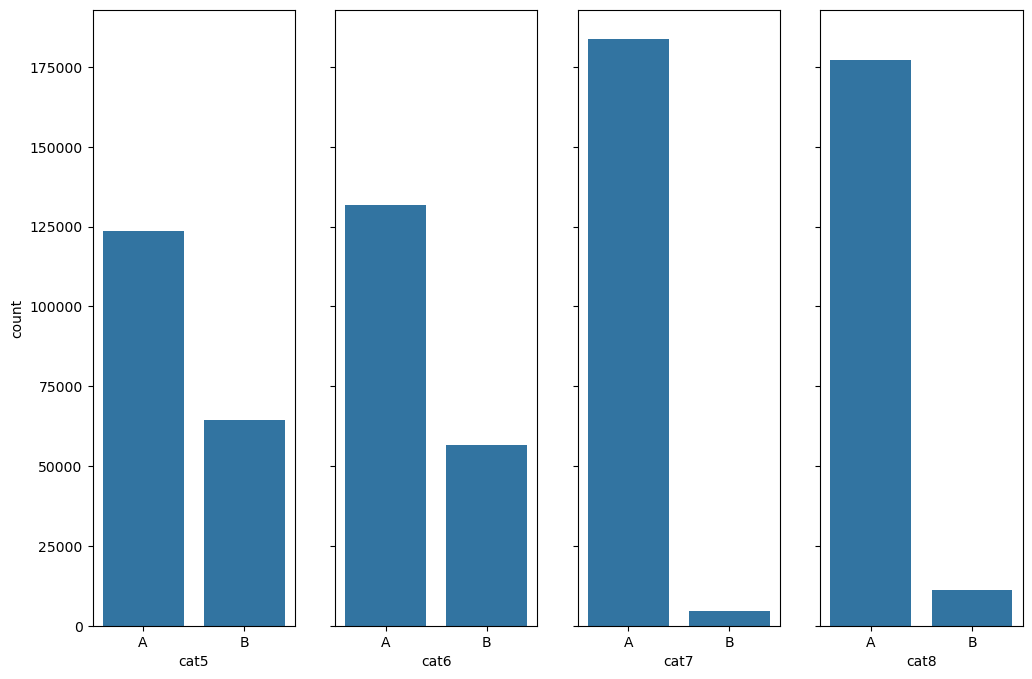

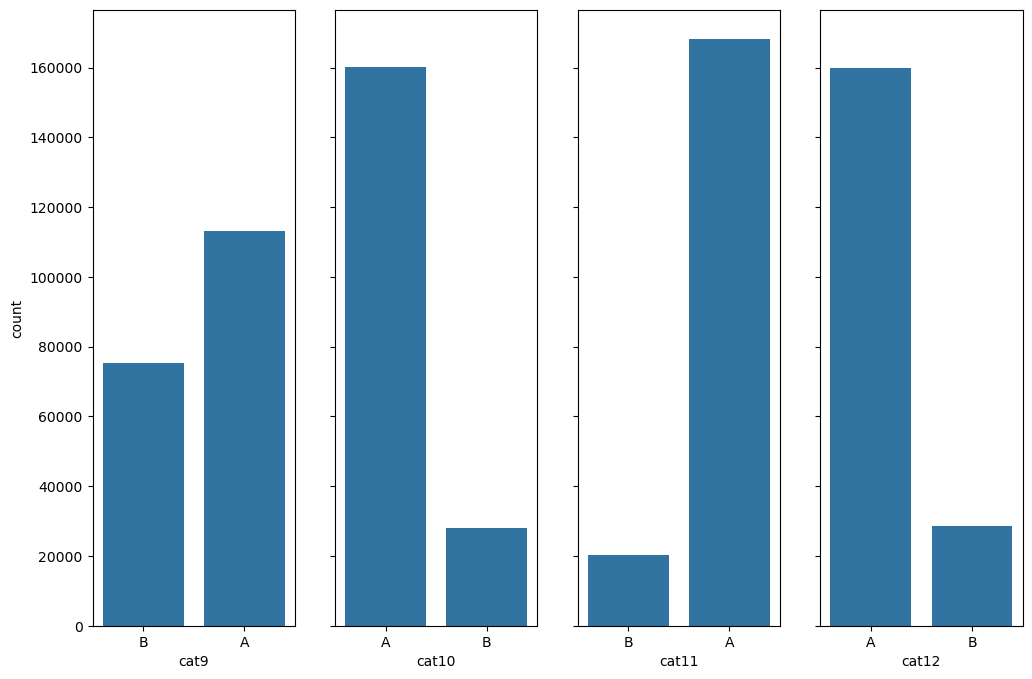

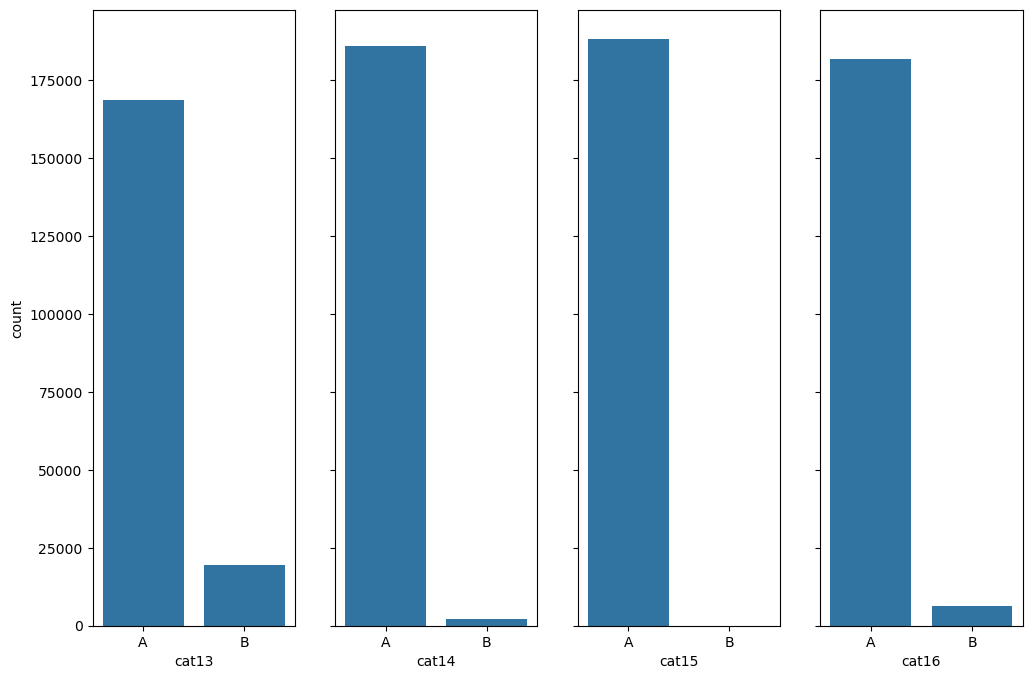

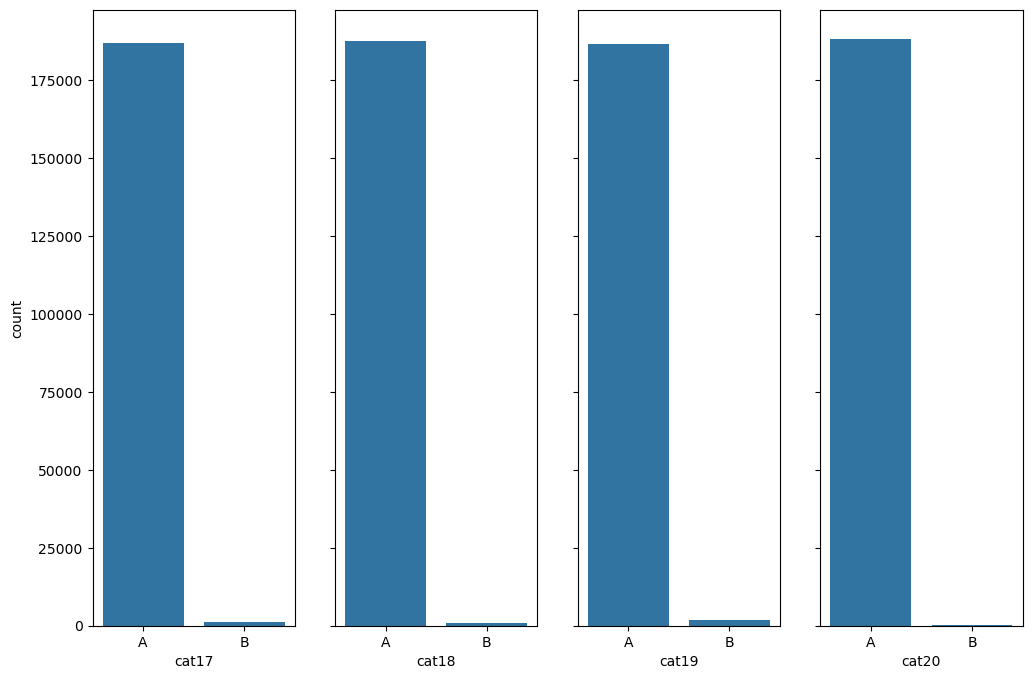

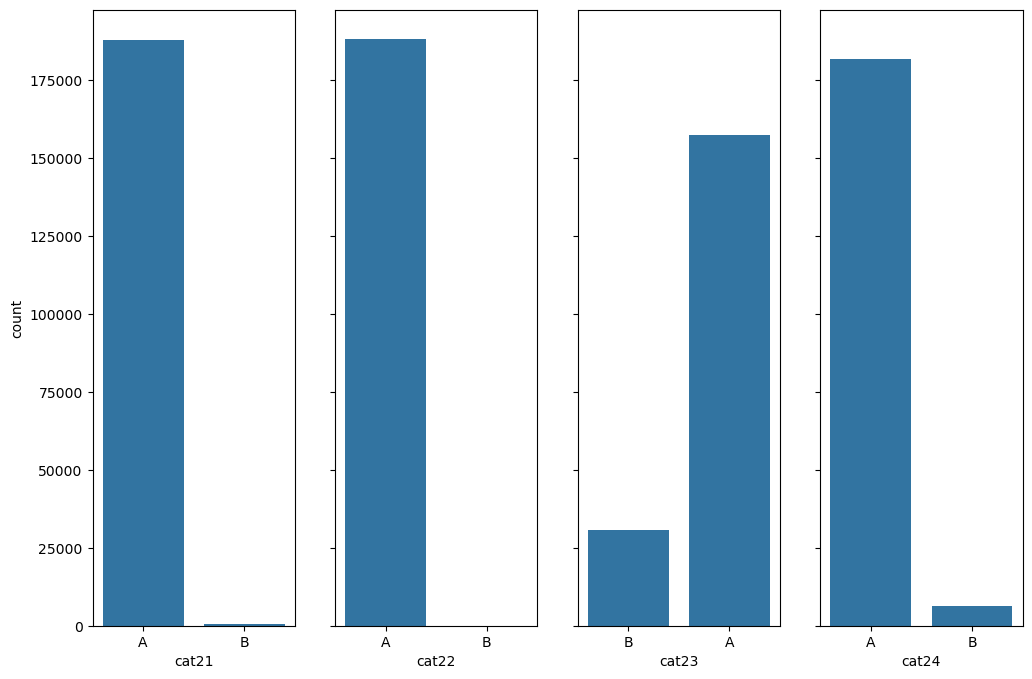

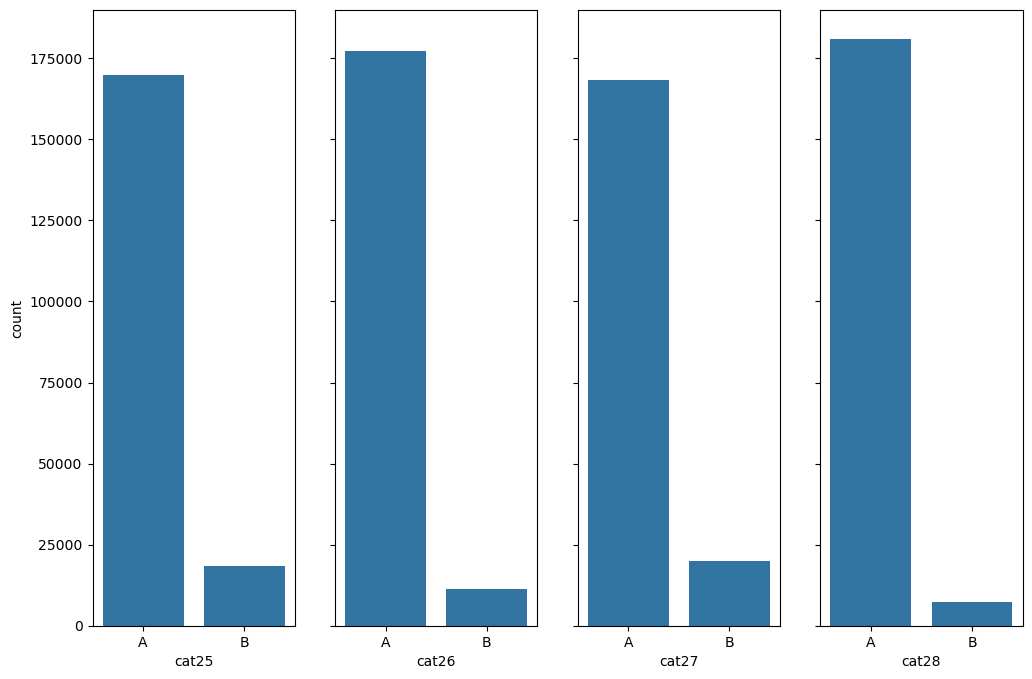

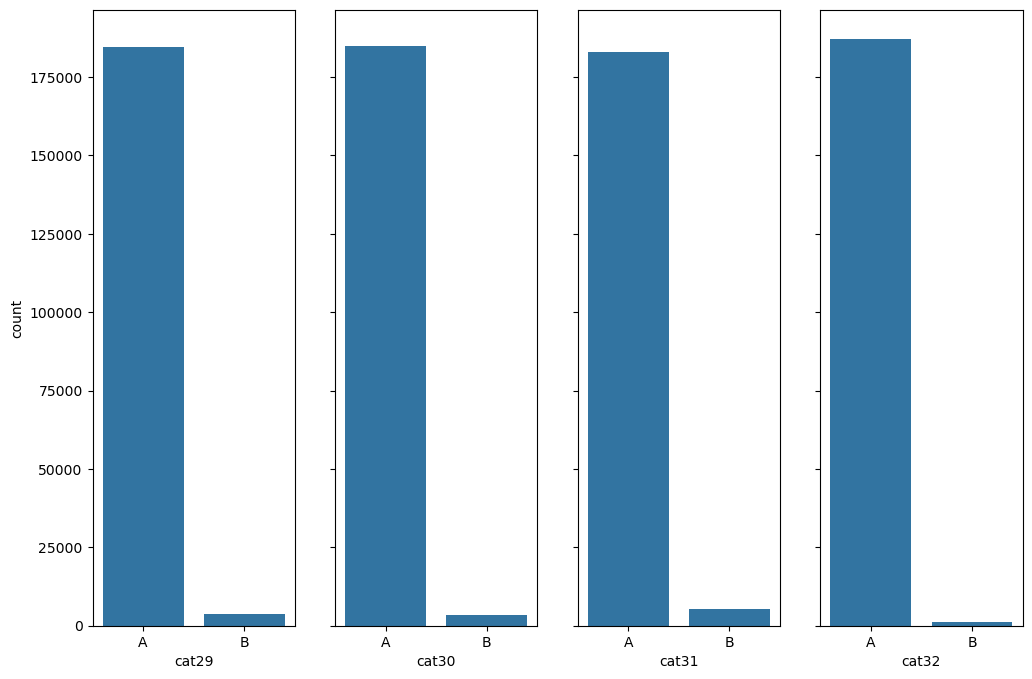

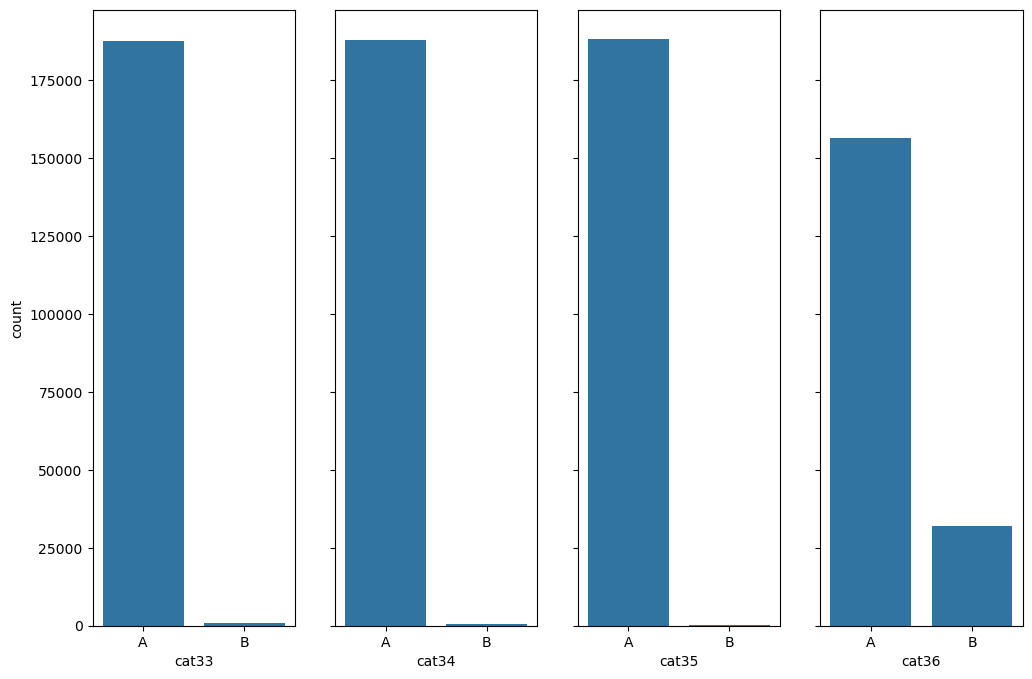

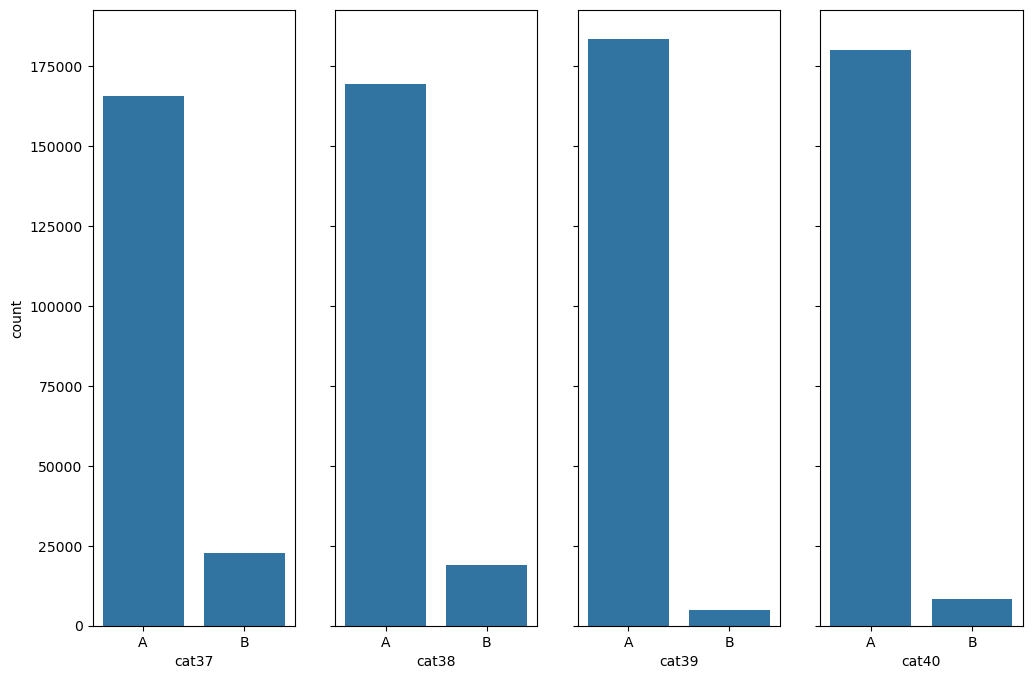

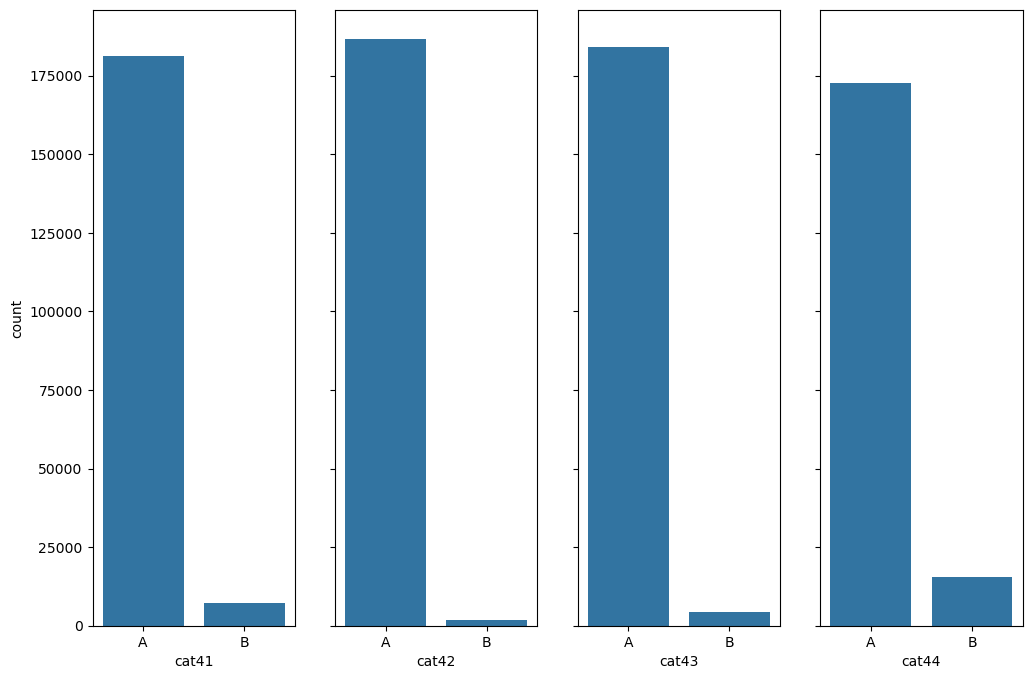

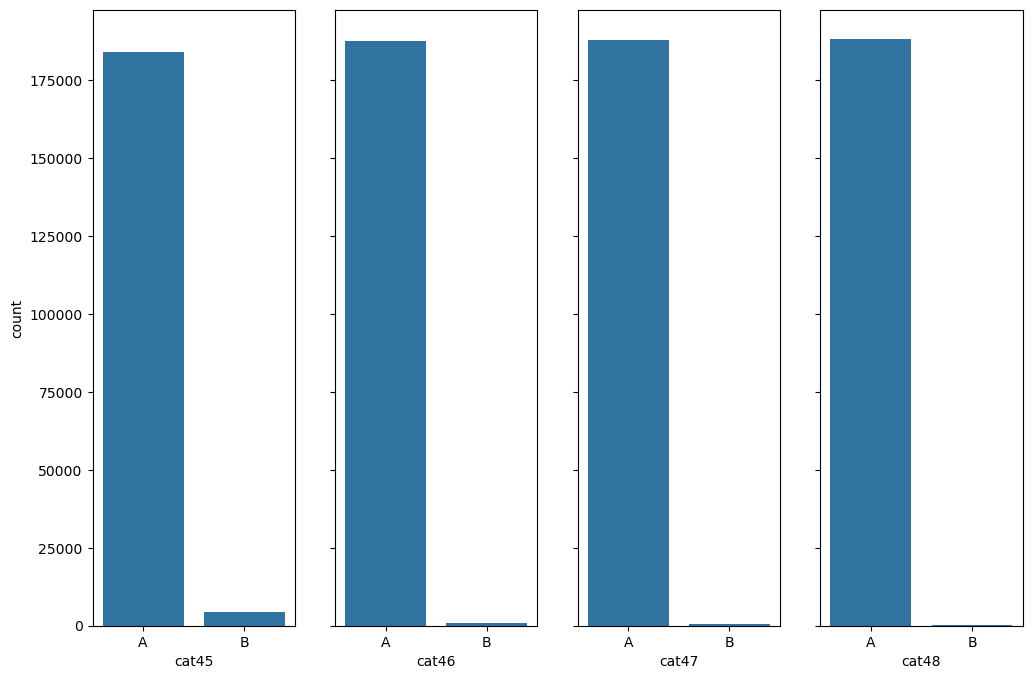

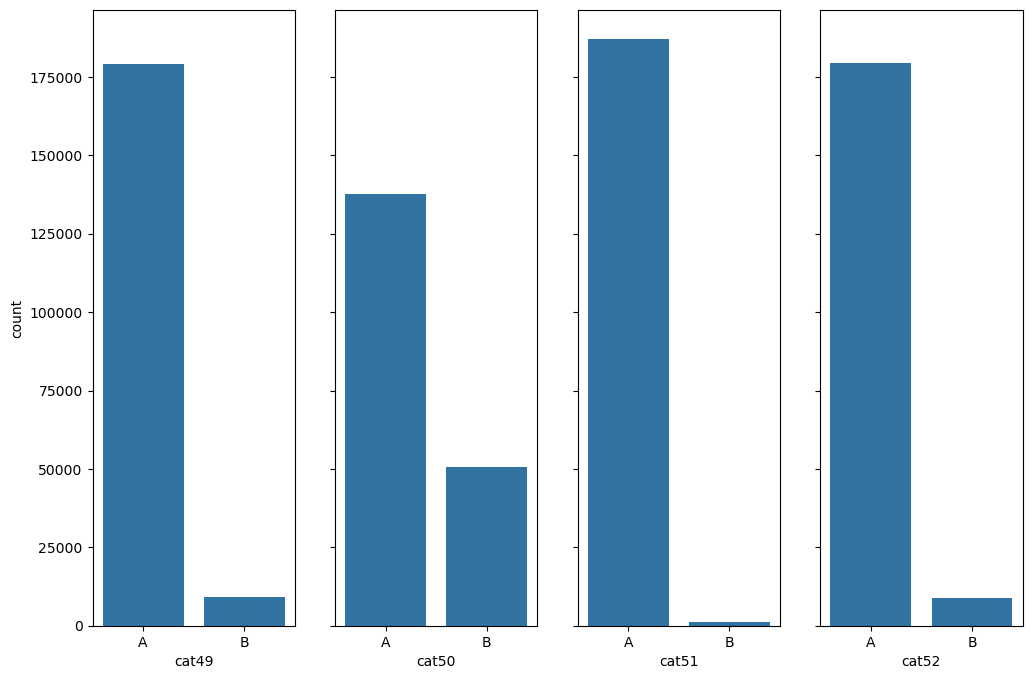

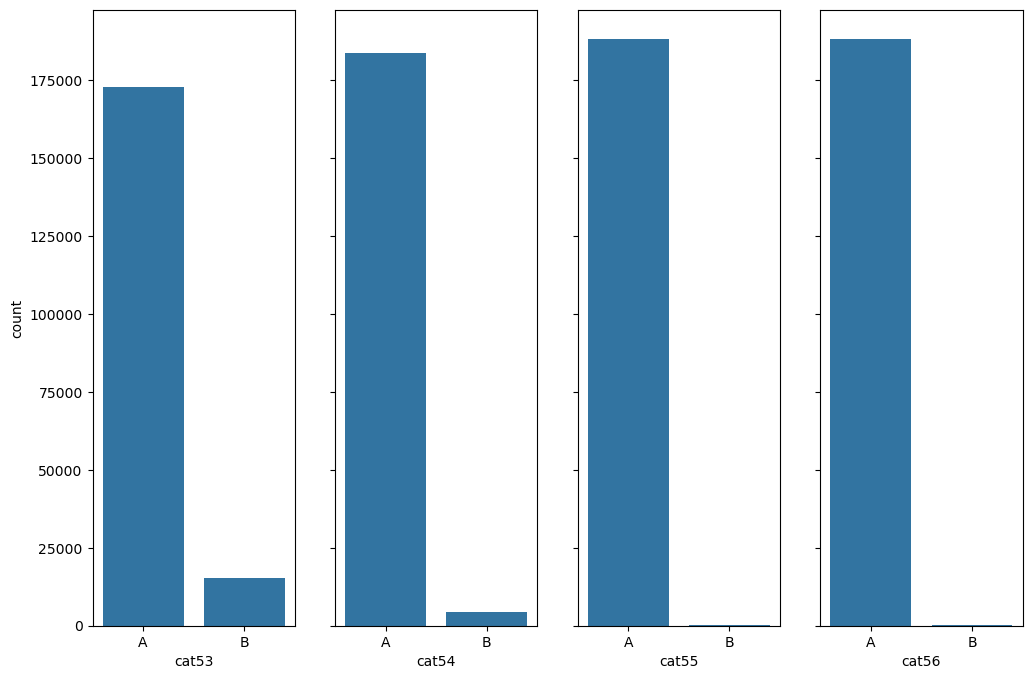

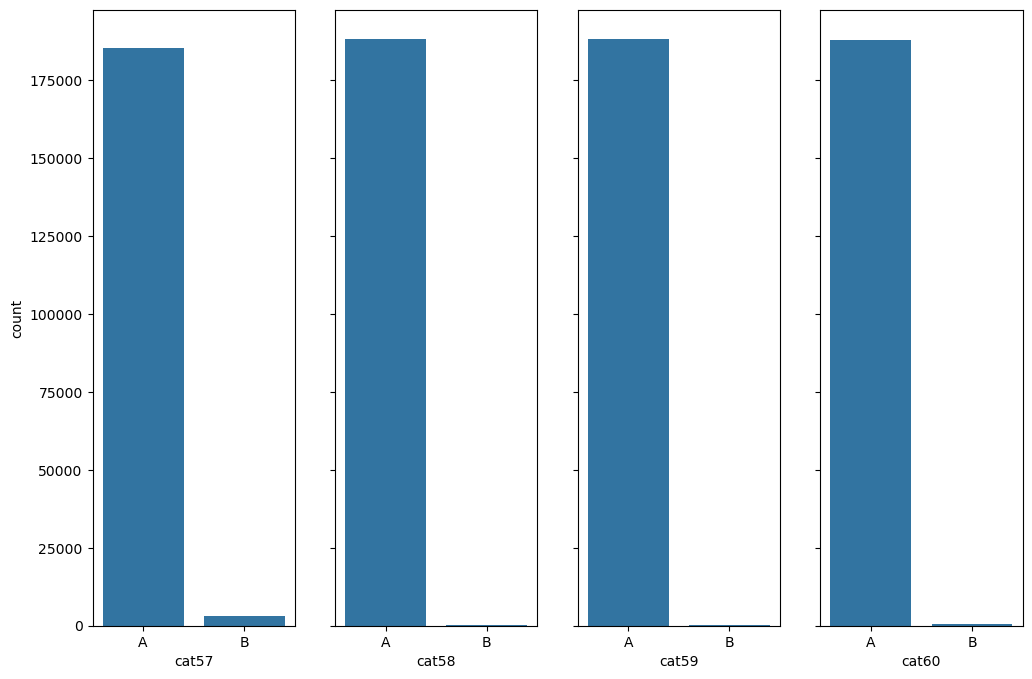

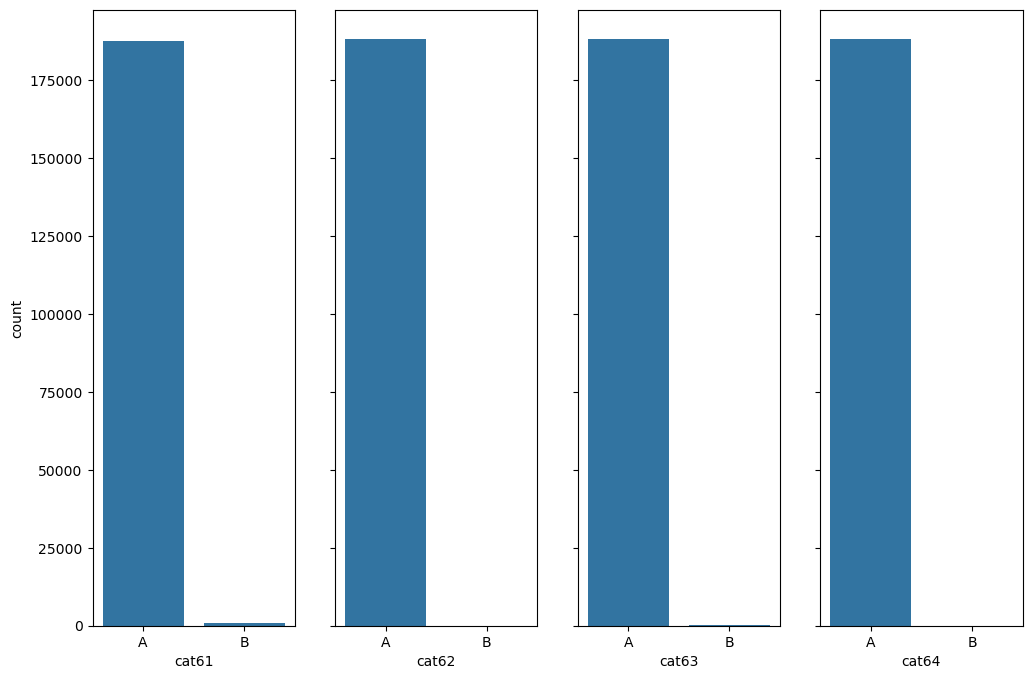

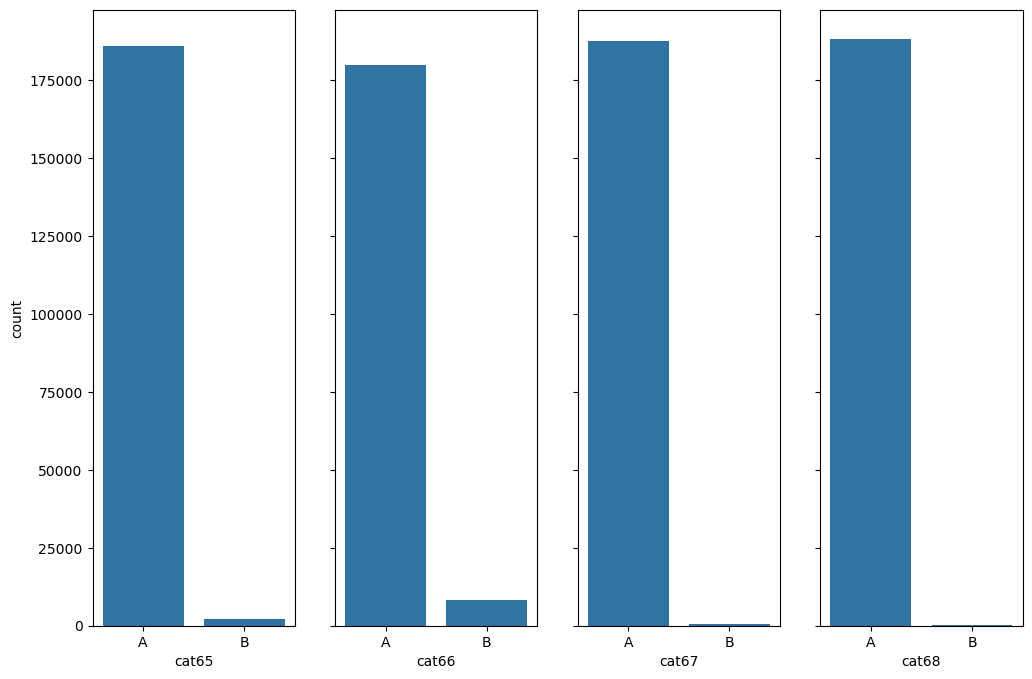

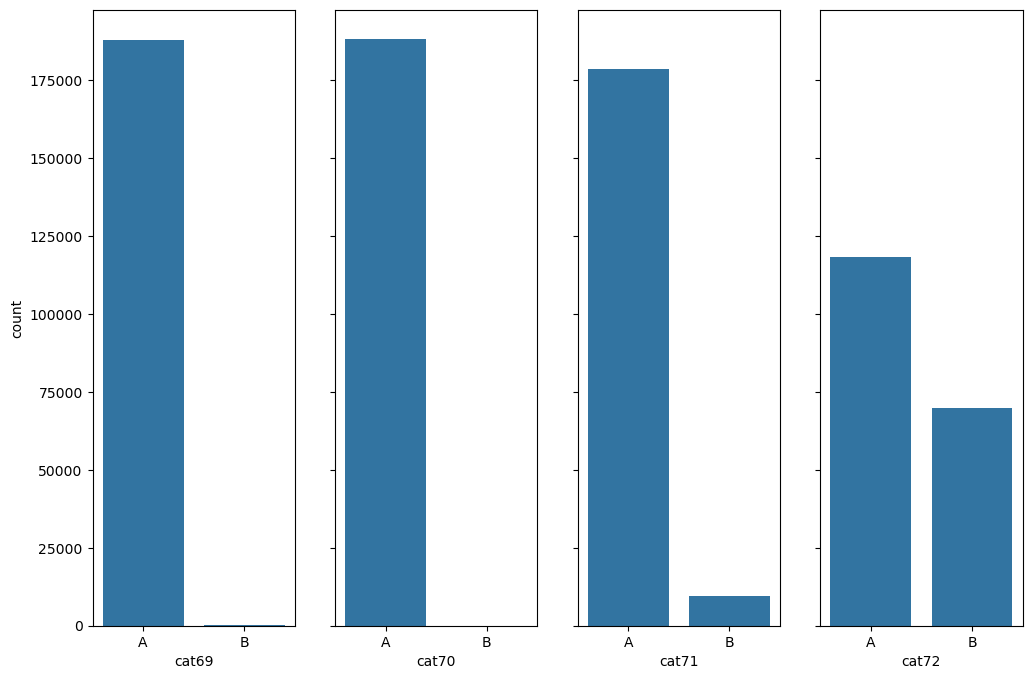

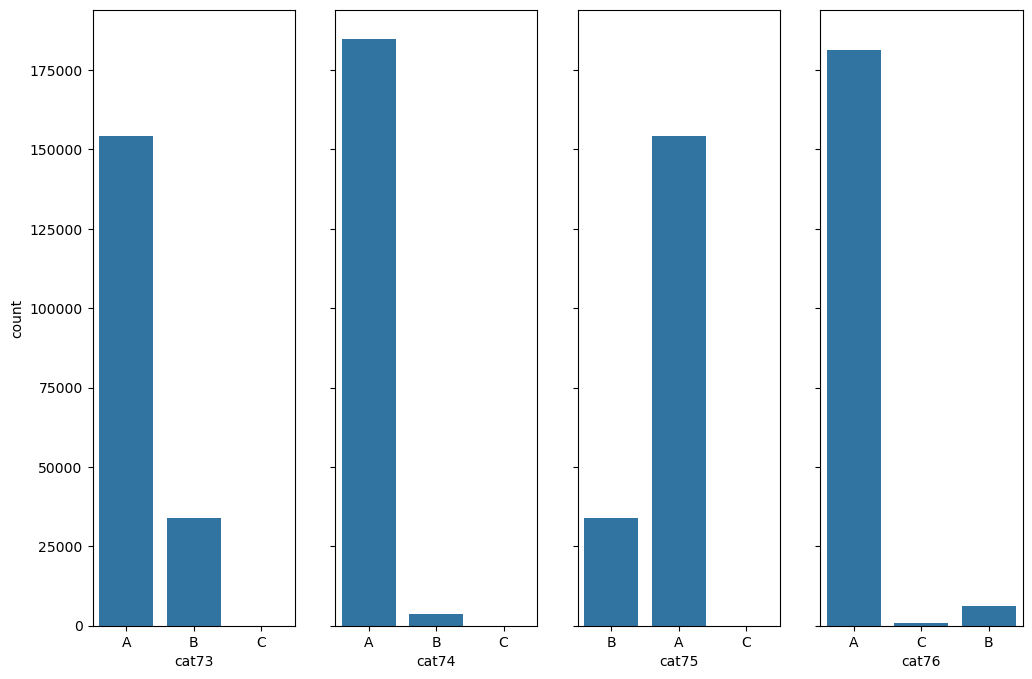

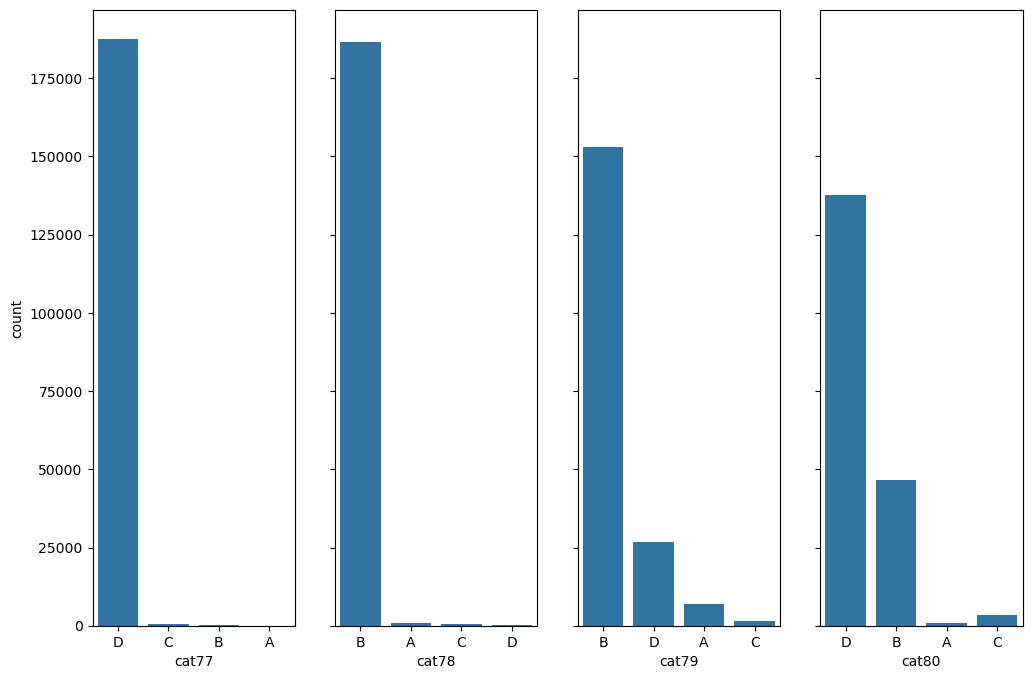

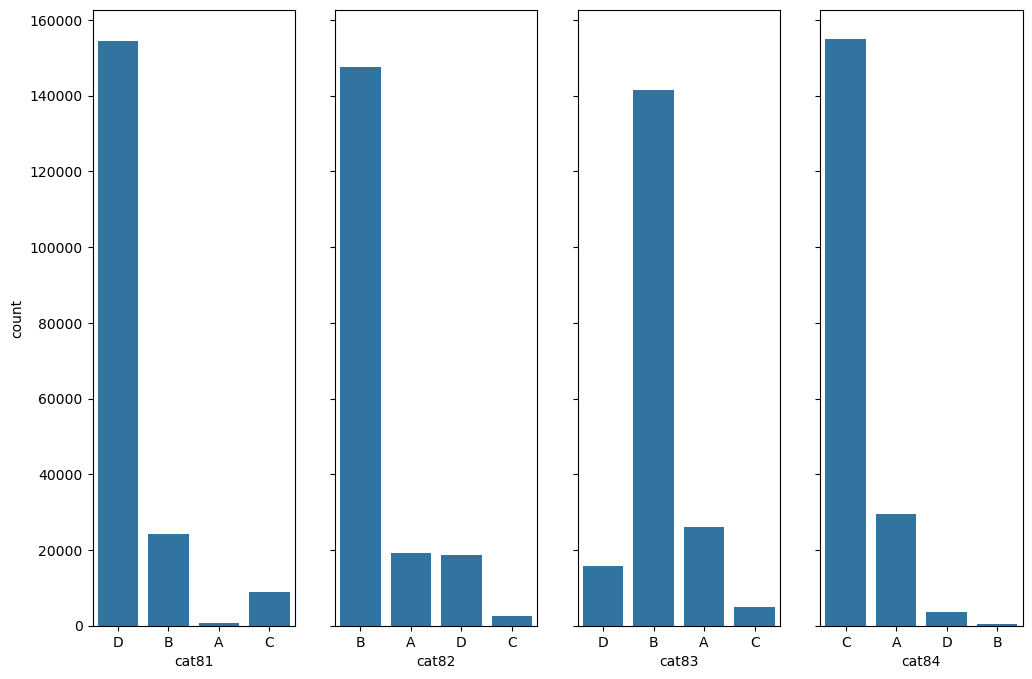

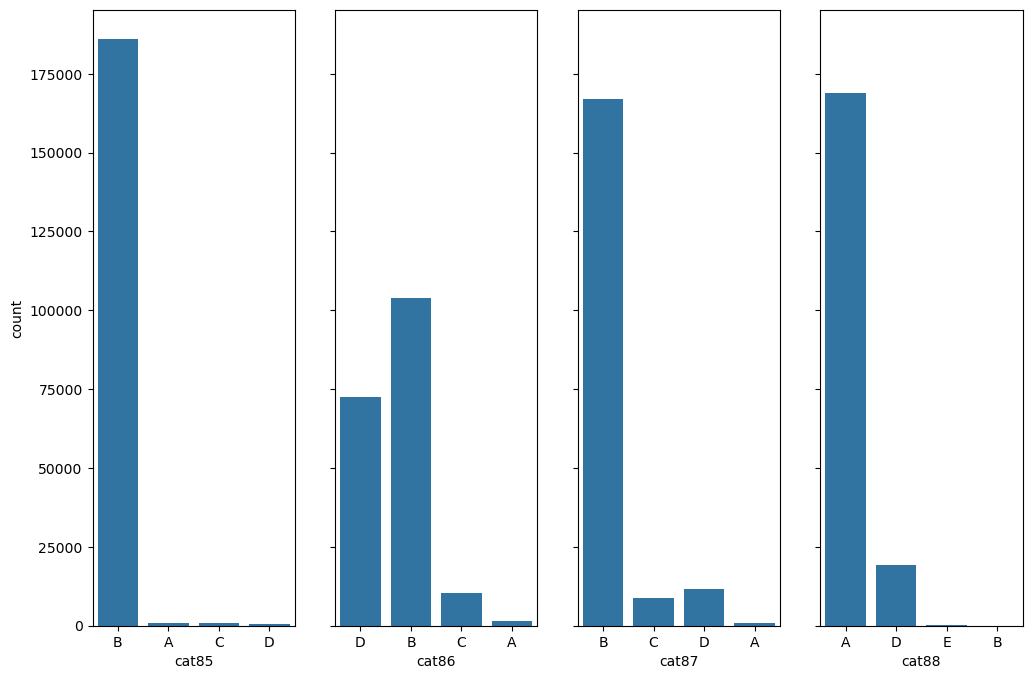

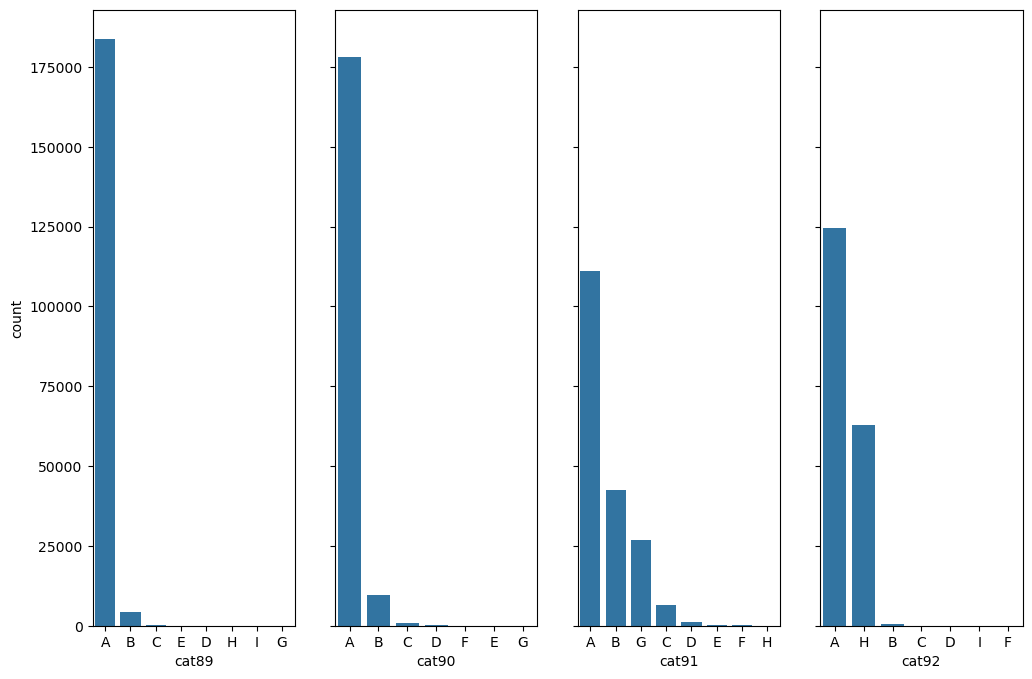

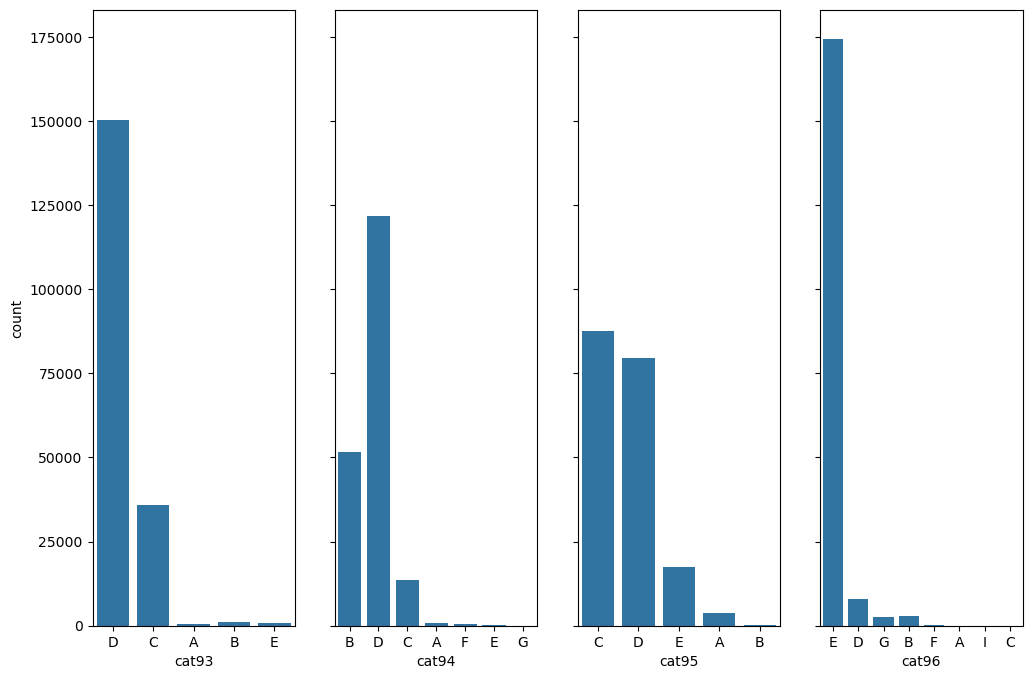

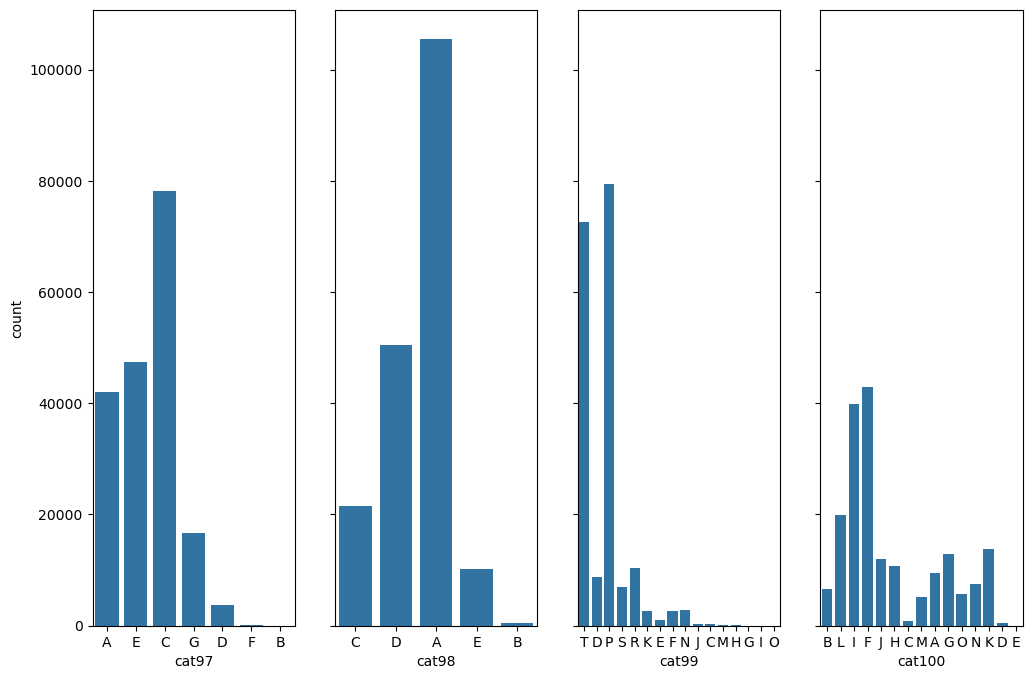

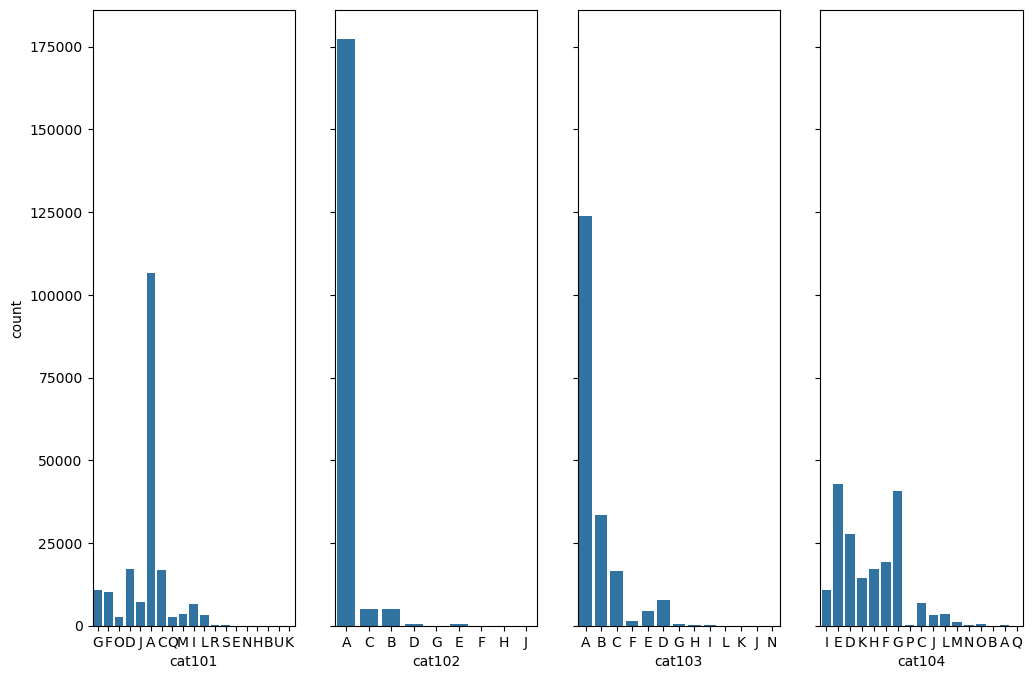

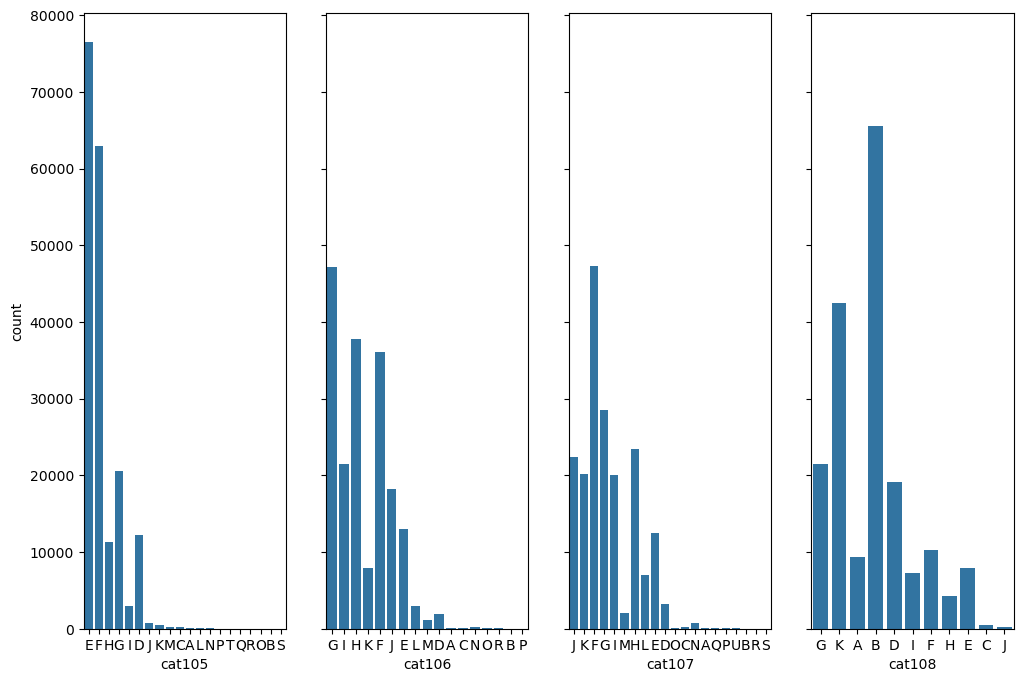

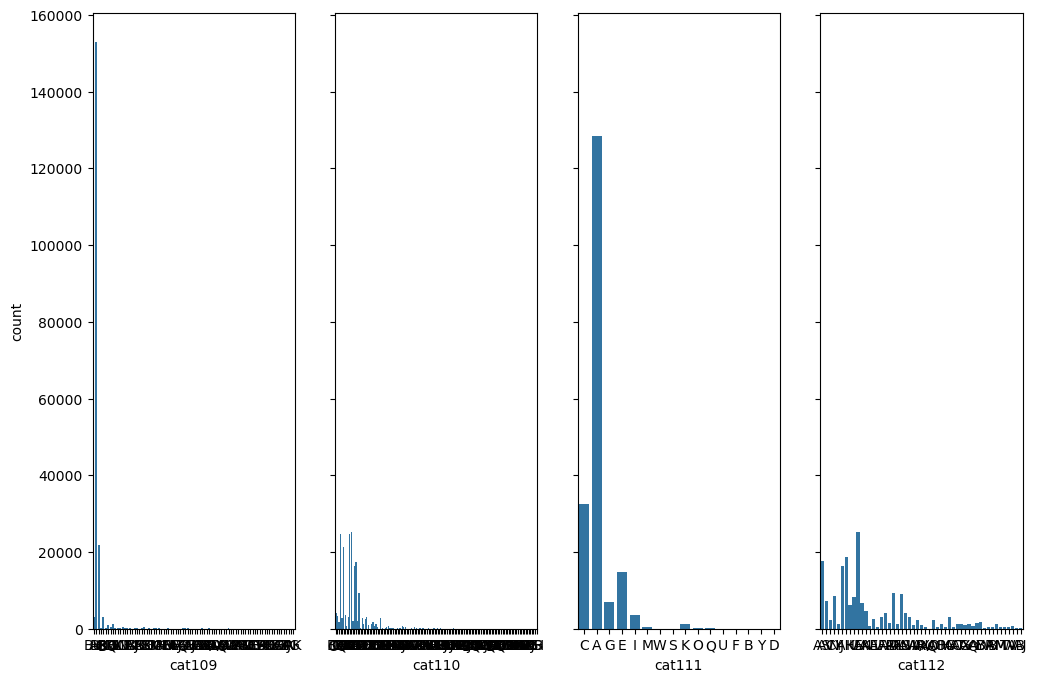

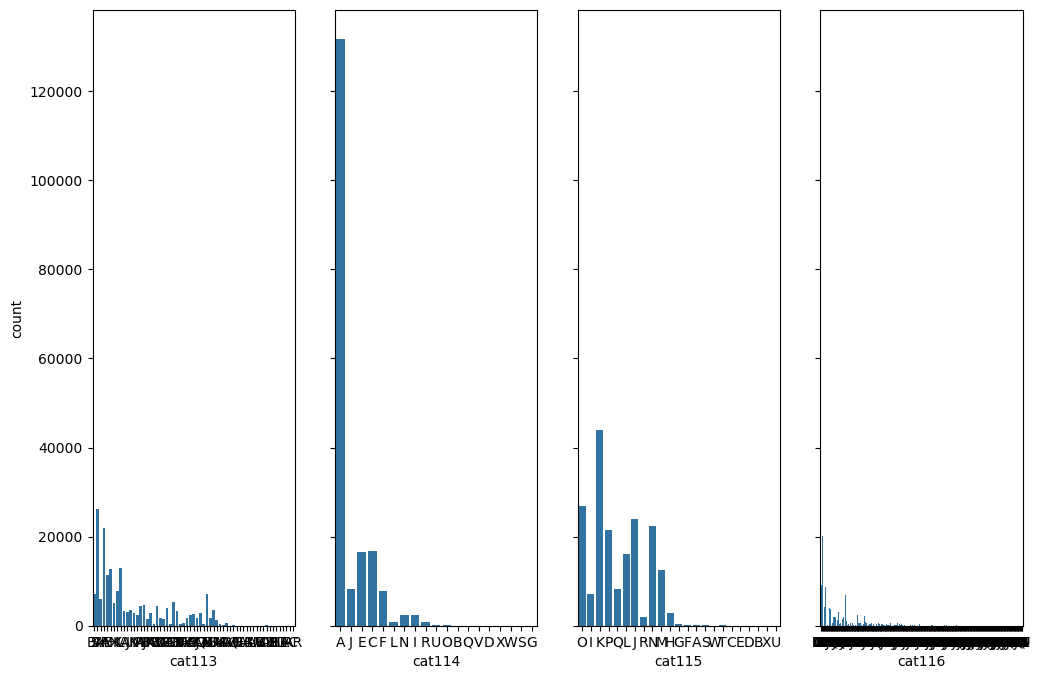

In [29]:
# Count of each label in each category

#names of all the columns
cols = dataset.columns

#Plot count plot for all attributes in a 29x4 grid
n_cols = 4
n_rows = 29
for i in range(n_rows):
    fg,ax = plt.subplots(nrows=1,ncols=n_cols,sharey=True,figsize=(12, 8))
    for j in range(n_cols):
        sns.countplot(x=cols[i*n_cols+j], data=dataset, ax=ax[j])

#cat1 to cat72 have only two labels A and B. In most of the cases, B has very few entries
#cat73 to cat 108 have more than two labels
#cat109 to cat116 have many labels

## Data Preparation